# How the phase-inference algorithm works, and where it stops working

*An explainer built on the stochastic Stuart–Landau oscillator.*

The paper infers three parameters from a noisy oscillatory signal: a frequency $\omega$, a phase diffusivity $D_\theta$ and a measurement-noise variance $R$. The inference model is
$$
\theta_{k+1}=\theta_k+\omega\Delta t+\varepsilon_k,\quad \varepsilon_k\sim\mathcal N(0,2D_\theta\Delta t),
\qquad
\mathbf y_k=\begin{pmatrix}\cos\theta_k\\ \sin\theta_k\end{pmatrix}+\boldsymbol\eta_k,\quad \boldsymbol\eta_k\sim\mathcal N(\mathbf 0,R\,\mathbf I_2).
$$
It is solved with an extended Kalman filter (EKF), an RTS smoother, generalized EM and a Laplace approximation (`StuartLandauPhaseInference.py`, `FastPhaseEM.py`).

This notebook answers three questions:

1. **What does the algorithm actually measure?** Which features of the data set each parameter, and how information about them flows through the filter.
2. **What happens when the data were *not* generated by this model?** Real oscillators have amplitude fluctuations and coloured phase noise.
3. **When can the numbers be trusted?** A regime map, and diagnostics you can compute on real data.
4. **Where does the bias come from, and when does it vanish?** §5b derives $D^\ast=D_{\rm eff}-(\ldots)/\Delta t$ term by term, §5c the fine-sampling limit $D^\ast\to D_x/2$, and §10 collects every asymptotic limit: when the model works out of the box, and what does *not* help.

The Stuart–Landau (SL) oscillator is the test bed because its stochastic phase reduction can be solved in closed form. Every claim below is checked against an analytical prediction. The central result (§5) is that the estimator converges to a **computable** point. That point is the member of the model family closest in Kullback–Leibler divergence to the true process. It reproduces the 1872-fit sweep in `data/sweep_results.parquet` to better than 1 %.

**Runtime:** about 3 min. Heavy sweeps are read from the cached parquet. Every fresh fit uses the same pipeline as the sweep (`NoiseInjectionSweep.fit_window`).

## 0 · Roadmap: a chain of approximations

The inference does not act on the oscillator directly. It acts on a chain of reduced descriptions, and each link carries an assumption that can fail.

| # | Step | Assumption | Fails when | § |
|---|---|---|---|---|
| A | SDE $\dot x=f(x)+G\xi$ → asymptotic phase $\Phi$, $\dot\Phi=\omega+\sqrt{2D_{\rm eff}}\,\xi$ | weak noise, $\sigma_\rho\ll1$ | noise comparable to the limit-cycle size | 1 |
| B | asymptotic phase → **projection phase** $\theta_p$ (what a waveform model can see) | $\theta_p$ and $\Phi$ differ by a bounded, coloured term | always; the gap matters at lags $\lesssim\tau_r$ | 1, 4 |
| C | $\theta_p$ → random walk + white, isotropic noise | no memory, isotropic residuals | amplitude noise is radial **and** coloured | 2, 4, 5 |
| D | EKF: linearise $\mathbf h$ about $\hat\theta_{k\mid k-1}$ | $2D\Delta t\ll1$ and $3P_{k\mid k-1}^2/8R\ll1$ | bias $\approx-(2\text{–}2.5)\times2D\Delta t$ in $\ln D$ (empirical slope); curvature inflates $R$; angular noise $\gtrsim0.5$ rad | 3d, 8 |
| E | generalized EM on the frozen linear surrogate | — | weak likelihood curvature in $D$, so slow convergence and a prior-dominated fixed point at small $N$ | 8 |
| F | Laplace: $\mathcal I=\mathcal I_{\rm prior}+\mathcal I_{\rm comp}-\mathcal I_{\rm miss}$ | the model is correct | model misspecified, so error bars are too narrow | 7 |

Examples 1a/1b of the supplement test only D–F, because their data come from the inference model itself (§3). The Stuart–Landau data test A–F together (§4–§8).

In [1]:
from dataclasses import replace
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import StuartLandauSimulation as SLS
import StuartLandauPhaseInference as SLPI
import FastPhaseEM
import NoiseInjectionSweep as NIS
import figstyle as fs

%config InlineBackend.figure_format = 'retina'
plt.rcParams.update({'font.size': 9, 'axes.titlesize': 9, 'legend.fontsize': 8,
                     'legend.frameon': False, 'axes.linewidth': 0.6})
T0_NOTEBOOK = time.time()

# ── physical parameters (identical to the Figure-2 sweep, NoiseInjectionSweep.Config) ──
cfg = NIS.Config()
a, b, Dx = cfg.a, cfg.b, cfg.Dx          # radial rate [1/time], shear [-], Cartesian diffusivity [length^2/time]
D_eff = Dx * (1 + b**2 / a**2)           # long-time phase diffusivity [rad^2/time]
tau_r = 1 / (2 * a)                      # radial relaxation time [time]
sig_rho2 = Dx / (2 * a)                  # stationary radial variance <rho^2> [length^2]
dt_inf = cfg.delta_t_inf                 # inference sampling interval [time]

# colour roles: one sequential map sampled at fixed points (house style)
C = {k: fs.CMAP(v) for k, v in dict(data=0.2, model=0.6, theory=0.0, extra=0.85).items()}
SEQ = lambda n: [fs.CMAP(v) for v in np.linspace(0.05, 0.85, n)]   # ordered series (e.g. increasing N)

sweep = pd.read_parquet('data/sweep_results.parquet').query("init_mode == 'default'")
assert sweep.converged.all(), 'every cached fit must have converged (section 8 relies on it)'
print(f"a = {a}, b = {b}, D_x = {Dx:.1e}  ->  D_eff = {D_eff:.1e} rad^2/time, "
      f"tau_r = {tau_r}, sigma_rho = {np.sqrt(sig_rho2):.4f}")
print(f"cached sweep: {len(sweep)} fits (default init), "
      f"N_INF in {sorted(sweep.N_INF.unique())}")

a = 1.0, b = 1.0, D_x = 1.0e-03  ->  D_eff = 2.0e-03 rad^2/time, tau_r = 0.5, sigma_rho = 0.0224
cached sweep: 936 fits (default init), N_INF in [np.int64(2000), np.int64(4000), np.int64(8000), np.int64(16000), np.int64(32000), np.int64(64000), np.int64(128000), np.int64(256000), np.int64(512000)]


## 1 · The Stuart–Landau oscillator and its three phases

### 1a · Dynamics and phase reduction
In polar coordinates $x=r(\cos\varphi,\sin\varphi)$ the deterministic dynamics are
$$
\dot r=a(r-r^3),\qquad \dot\varphi=1+b(r^2-1),
$$
with a stable limit cycle at $r=1$ and frequency $\omega_0=1$. We add isotropic Cartesian noise, $\dot{\mathbf x}=f(\mathbf x)+\sqrt{2D_x}\,\boldsymbol\xi$. Linearising about the cycle with $r=1+\rho$ gives
$$
d\rho=-2a\rho\,dt+\sqrt{2D_x}\,dW_r,\qquad d\varphi=(1+2b\rho)\,dt+\sqrt{2D_x}\,dW_\varphi .
$$
The radial deviation $\rho$ is an Ornstein–Uhlenbeck process, with relaxation time $\tau_r=1/2a$ and variance $\sigma_\rho^2=D_x/2a$.

There are three phase-like variables:

* **Geometric (projection) phase** $\theta_p=\varphi$, the polar angle. A waveform model $y_0(\theta)=(\cos\theta,\sin\theta)$ can only ever see this one. It is the point on the limit cycle closest to the measurement.
* **Asymptotic phase** $\Phi=\varphi+\frac{b}{a}\ln r\approx\varphi+\frac{b}{a}\rho$. Its level sets are the isochrons. Using Itô's rule and $\nabla^2\ln r=0$,
$$
d\Phi=dt+\sqrt{2D_x}\Big(dW_\varphi+\tfrac{b}{a}dW_r\Big)\quad\Longrightarrow\quad
D_{\rm eff}=D_x\Big(1+\frac{b^2}{a^2}\Big).
$$
$\Phi$ is an exact random walk. **This is the "true" phase diffusion the paper wants.**
* **Inferred phase** $\hat\theta_{k\mid N}$, the smoother's estimate. §2 shows it tracks $\theta_p$, not $\Phi$.

The two physical phases differ by a bounded, coloured term:
$$
\theta_p=\Phi-\frac{b}{a}\rho .
$$

### 1b · The key formula: stationary MSD of the observable phase
$\Phi$ diffuses with $D_{\rm eff}$ at every lag. $\theta_p$ inherits the OU memory of $\rho$. For a **stationary** trajectory, using $\mathrm{Cov}(\Delta\Phi,\Delta\rho)=2\frac{b}{a}\sigma_\rho^2(1-e^{-2a\tau})$,
$$
\boxed{\;\mathrm{MSD}_{\theta_p}(\tau)=2D_{\rm eff}\,\tau\;-\;2\frac{b^2}{a^2}\sigma_\rho^2\big(1-e^{-2a\tau}\big)\;}
$$

* **Short lags** ($\tau\ll\tau_r$): $\mathrm{MSD}\approx 2D_x\tau$. Only direct tangential kicks are visible.
* **Long lags** ($\tau\gg\tau_r$): $\mathrm{MSD}\approx 2D_{\rm eff}\tau-2(b/a)^2\sigma_\rho^2$, which is a **negative intercept**.

Keep that negative intercept in mind. White measurement noise of variance $R$ adds a *positive* intercept $+2R$. The coloured part of $\theta_p$ therefore behaves like *negative* measurement noise at long lags, which no member of the inference model can represent. Most of what follows comes from this mismatch.

> `StuartLandauSimulation.theoretical_curves` gives the *non-stationary* version, for trajectories started on the cycle with $\rho(0)=0$. Below we discard a burn-in of $10\,\tau_r$ and compare against the stationary formula.

Var[rho] = 5.094e-04   theory D_x/2a = 5.000e-04
MSD_theta_p: rms relative deviation from the stationary formula over 0 < tau <= 5: 0.015   (single-origin sampling error ~ sqrt(2/M) = 0.071)


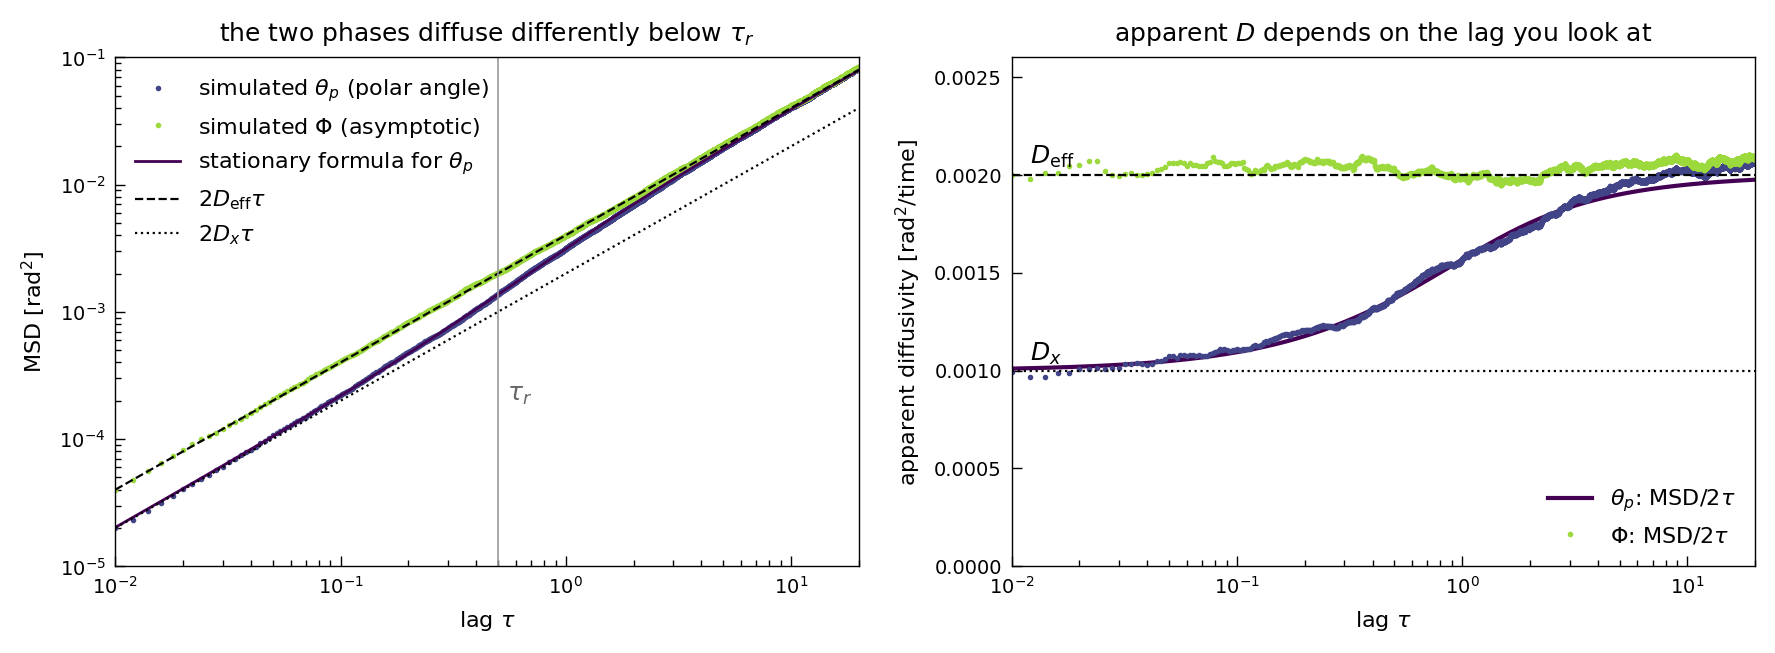

In [2]:
def msd_theta_p(tau: np.ndarray, a: float, b: float, Dx: float) -> np.ndarray:
    # Stationary MSD of the geometric phase theta_p = Phi - (b/a) rho  [rad^2].
    #
    # Parameters
    # ----------
    # tau : lag times [time]
    # a, b : SL radial rate [1/time] and shear [-]
    # Dx : isotropic Cartesian diffusivity [length^2/time]
    D_eff = Dx * (1 + b**2 / a**2)
    return 2 * D_eff * tau - 2 * (b / a)**2 * (Dx / (2 * a)) * (1 - np.exp(-2 * a * tau))


# ensemble of M trajectories, Euler-Maruyama at dt = 0.002, burn-in 10 tau_r
# MSD averaged over realisations AND over 9 time origins (stationary after 10 tau_r)
M, dt_sim, T_sim, L_max = 400, 0.002, 65.0, 20.0
t, x1, x2, r, theta, Phi = SLS.simulate_stuart_landau(a, b, Dx, dt_sim, int(T_sim / dt_sim), M, seed=7)
n_lag = int(L_max / dt_sim) + 1
lag = t[:n_lag]
omega_emp = np.mean(Phi[:, -1] - Phi[:, 0]) / t[-1]               # remove the mean drift
msd_phi, msd_Phi = np.zeros(n_lag), np.zeros(n_lag)
origins = [int(t0 / dt_sim) for t0 in np.arange(5.0, 45.0 + 1e-9, 5.0)]
for i0 in origins:
    msd_phi += np.mean((theta[:, i0:i0 + n_lag] - theta[:, [i0]] - omega_emp * lag)**2, axis=0)
    msd_Phi += np.mean((Phi[:, i0:i0 + n_lag] - Phi[:, [i0]] - omega_emp * lag)**2, axis=0)
msd_phi /= len(origins); msd_Phi /= len(origins)
var_rho = np.var(r[:, origins[0]:] - 1)
del x1, x2

sel = (lag > 0) & (lag <= 5)
rel_dev = msd_phi[sel] / msd_theta_p(lag[sel], a, b, Dx) - 1
print(f"Var[rho] = {var_rho:.3e}   theory D_x/2a = {sig_rho2:.3e}")
print(f"MSD_theta_p: rms relative deviation from the stationary formula over 0 < tau <= 5: "
      f"{np.sqrt(np.mean(rel_dev**2)):.3f}   (single-origin sampling error ~ sqrt(2/M) = {np.sqrt(2/M):.3f})")
assert abs(var_rho / sig_rho2 - 1) < 0.05
assert np.sqrt(np.mean(rel_dev**2)) < 2 * np.sqrt(2 / M)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
tt = np.geomspace(0.01, 20, 300)
ax = axs[0]
ax.loglog(lag[1:], msd_phi[1:], '.', ms=2, color=C['data'], label=r'simulated $\theta_p$ (polar angle)')
ax.loglog(lag[1:], msd_Phi[1:], '.', ms=2, color=C['extra'], label=r'simulated $\Phi$ (asymptotic)')
ax.loglog(tt, msd_theta_p(tt, a, b, Dx), '-', lw=1, color=C['theory'], label=r'stationary formula for $\theta_p$')
ax.loglog(tt, 2 * D_eff * tt, '--', lw=0.8, color='k', label=r'$2D_{\rm eff}\tau$')
ax.loglog(tt, 2 * Dx * tt, ':', lw=0.8, color='k', label=r'$2D_x\tau$')
ax.axvline(tau_r, color='0.6', lw=0.6); ax.text(tau_r * 1.1, 2e-4, r'$\tau_r$', color='0.4')
ax.set_xlim(0.01, 20); ax.set_ylim(1e-5, 0.1)
fs.style_axes(ax, r'lag $\tau$', r'MSD [rad$^2$]'); ax.legend(loc='upper left')
ax.set_title('the two phases diffuse differently below $\\tau_r$')

ax = axs[1]
ax.semilogx(tt, msd_theta_p(tt, a, b, Dx) / (2 * tt), '-', color=C['theory'], label=r'$\theta_p$: MSD$/2\tau$')
ax.semilogx(lag[1:], msd_phi[1:] / (2 * lag[1:]), '.', ms=2, color=C['data'])
ax.semilogx(lag[1:], msd_Phi[1:] / (2 * lag[1:]), '.', ms=2, color=C['extra'], label=r'$\Phi$: MSD$/2\tau$')
ax.axhline(D_eff, ls='--', color='k', lw=0.8); ax.axhline(Dx, ls=':', color='k', lw=0.8)
ax.text(0.012, D_eff * 1.03, r'$D_{\rm eff}$'); ax.text(0.012, Dx * 1.05, r'$D_x$')
ax.set_xlim(0.01, 20); ax.set_ylim(0, 2.6e-3)
fs.style_axes(ax, r'lag $\tau$', r'apparent diffusivity [rad$^2$/time]'); ax.legend(loc='lower right')
ax.set_title('apparent $D$ depends on the lag you look at')
fig.tight_layout(); plt.show()

**Reading the figure.** The observable phase $\theta_p$ looks like a diffusion with $D_x$ at lags below $\tau_r$ and with $D_{\rm eff}=2D_x$ at lags above it. $\Phi$ diffuses with $D_{\rm eff}$ everywhere. An inference that relies mostly on short-lag information will therefore report something near $D_x$, or lower (see §5). One that relies on long-lag information will report $D_{\rm eff}$. *Which lags the inference relies on* is set by the noise level, as we show in §3.

### 1c · A note on the frequency
Second-order phase reduction predicts a noise-induced frequency shift $\Delta\omega=\tfrac12\langle\mathrm{Tr}(C\,\nabla^2\Phi)\rangle$. For isotropic additive noise $C\propto I$, and $\nabla^2\Phi=\nabla^2\varphi+\frac{b}{a}\nabla^2\ln r=0$, because both are harmonic in 2D. So **$\Delta\omega=0$ for this model.** The supplement's $\Delta\omega=(b/a)D_x$ does not apply to additive isotropic noise.

Equivalently, $\langle\dot\varphi\rangle=1+b\langle r^2-1\rangle$, and Itô's rule gives $\langle r^2-1\rangle=0$ to leading order. The simulator does show a shift, $\omega_{\rm sim}-1\approx b\,dt/2a$, but this is an Euler–Maruyama artefact (each explicit rotation step inflates $r^2$ by $1+dt^2$). It is consistent with zero as $dt\to0$, as the check below confirms (intercept $-4\pm2\times10^{-4}$). Note that $(b/a)D_x=10^{-3}$ happens to equal $b\,dt/2a$ at the sweep's $dt=0.002$, so a single-$dt$ measurement cannot tell the two apart; only the $dt$-scan can. This matters because "ω is unbiased" claims must be judged against $\omega_{\rm sim}$, not against $1+(b/a)D_x$.

In [3]:
def mean_r2_shift(dt: float, T: float, M: int, burn: float, seed: int) -> tuple[float, float]:
    # <r^2 - 1> from the same Euler-Maruyama scheme as SLS.simulate_stuart_landau, accumulated
    # on the fly (no trajectory storage).  Returns (mean, standard error over realisations).
    rng = np.random.default_rng(seed)
    x1, x2 = np.ones(M), np.zeros(M)
    acc, n_acc, amp = np.zeros(M), 0, np.sqrt(2 * Dx * dt)
    for n in range(int(T / dt)):
        r2 = x1**2 + x2**2
        fac = 1 + b * (r2 - 1)
        x1, x2 = (x1 + (a * (1 - r2) * x1 - fac * x2) * dt + amp * rng.standard_normal(M),
                  x2 + (a * (1 - r2) * x2 + fac * x1) * dt + amp * rng.standard_normal(M))
        if n * dt >= burn:
            acc += x1**2 + x2**2 - 1
            n_acc += 1
    per_traj = acc / n_acc
    return per_traj.mean(), per_traj.std(ddof=1) / np.sqrt(M)


rows = []
for dt_i in (0.004, 0.002, 0.001):
    m_, s_ = mean_r2_shift(dt_i, T=40.0, M=2000, burn=5.0, seed=11)   # omega - 1 = b <r^2 - 1>
    rows.append((dt_i, b * m_, b * s_))
dts, shift, se = map(np.array, zip(*rows))
p, pcov = np.polyfit(dts, shift, 1, w=1 / se, cov='unscaled')
for d_, s_, e_ in rows:
    print(f"dt = {d_:.3f}:  omega_sim - 1 = {s_:+.2e} +/- {e_:.1e}    Euler-Maruyama prediction b dt/2a = {b*d_/(2*a):.1e}")
print(f"extrapolated to dt -> 0: {p[1]:+.1e} +/- {np.sqrt(pcov[1, 1]):.1e}    (supplement's (b/a) D_x would give {b/a*Dx:.0e})")
assert abs(p[1]) < abs(p[1] - b / a * Dx)   # the intercept is closer to 0 than to (b/a) D_x

dt = 0.004:  omega_sim - 1 = +2.12e-03 +/- 1.7e-04    Euler-Maruyama prediction b dt/2a = 2.0e-03
dt = 0.002:  omega_sim - 1 = +9.77e-04 +/- 1.7e-04    Euler-Maruyama prediction b dt/2a = 1.0e-03
dt = 0.001:  omega_sim - 1 = +2.04e-04 +/- 1.7e-04    Euler-Maruyama prediction b dt/2a = 5.0e-04
extrapolated to dt -> 0: -3.7e-04 +/- 2.0e-04    (supplement's (b/a) D_x would give 1e-03)


## 2 · The inference model, and what the EKF actually "sees"

### 2a · Filter, smoother, likelihood (one line each)
* **Predict:** $\hat\theta_{k\mid k-1}=\hat\theta_{k-1\mid k-1}+\omega\Delta t$ and $P_{k\mid k-1}=P_{k-1\mid k-1}+2D\Delta t$.
* **Linearise:** $\mathbf h(\theta)\approx\mathbf c_k+\mathbf H_k\theta$, with $\mathbf H_k=(-\sin\hat\theta_{k\mid k-1},\cos\hat\theta_{k\mid k-1})^\top$ and $\mathbf c_k=\mathbf h(\hat\theta_{k\mid k-1})-\mathbf H_k\hat\theta_{k\mid k-1}$.
* **Update:** this is the standard Kalman update with innovation covariance $\mathbf S_k=\mathbf H_kP_{k\mid k-1}\mathbf H_k^\top+R\mathbf I_2$.
* **Likelihood:** $\log p(\mathbf y_{1:N}\mid\lambda)=\sum_k\log\mathcal N(\mathbf y_k;\mathbf h(\hat\theta_{k\mid k-1}),\mathbf S_k)$.
* **Smooth:** an RTS backward pass gives $\hat\theta_{k\mid N}$, $P_{k\mid N}$ and the lag-one covariances.
* **EM:** expected sufficient statistics → closed-form updates for $\omega$, $D$ and $R$; relinearise; repeat.

### 2b · The identity that explains everything: two channels
Because $\lVert\mathbf H_k\rVert=1$ and $\mathbf H_k\perp\mathbf h(\hat\theta_{k\mid k-1})$, the 2D measurement splits exactly into two scalar channels. Write $\mathbf y_k=r_k(\cos\psi_k,\sin\psi_k)$, so $\psi_k$ is the measured angle, and $\delta_k=\psi_k-\hat\theta_{k\mid k-1}$:
$$
\underbrace{z_k=\mathbf H_k^\top(\mathbf y_k-\mathbf c_k)=\hat\theta_{k\mid k-1}+r_k\sin\delta_k\;\approx\;\psi_k}_{\text{tangential: a noisy observation of the angle}}
\qquad
\underbrace{o_k=\lVert\mathbf y_k-\mathbf c_k\rVert^2-z_k^2=(r_k\cos\delta_k-1)^2\;\approx\;(r_k-1)^2}_{\text{radial: contains no phase information}}
$$
The phase is learned **only** from $z_k$, a scalar random walk observed in noise (Example 1a). The radial channel enters **only** through the EM update for $R$:
$$
R^{\rm new}=\frac{\sum_k\big(\mathbb E[(z_k-\theta_k)^2]+o_k\big)+2\beta_R}{2(N+\alpha_R)}
\;\approx\;\tfrac12\big(\underbrace{\overline{(z-\theta)^2}}_{\text{tangential residual}}+\underbrace{\overline{(r-1)^2}}_{\text{radial residual}}\big).
$$
**A single $R$ is shared by both channels.** If the noise really is isotropic, the radial channel is free extra information about $R$ (§3 shows this is what makes $R$ and $D$ nearly uncorrelated in Example 1b). If the radial residual comes from *amplitude fluctuations* rather than instrument noise, the radial channel feeds a wrong $R$ into the phase filter.

We now check these identities on an SL window.

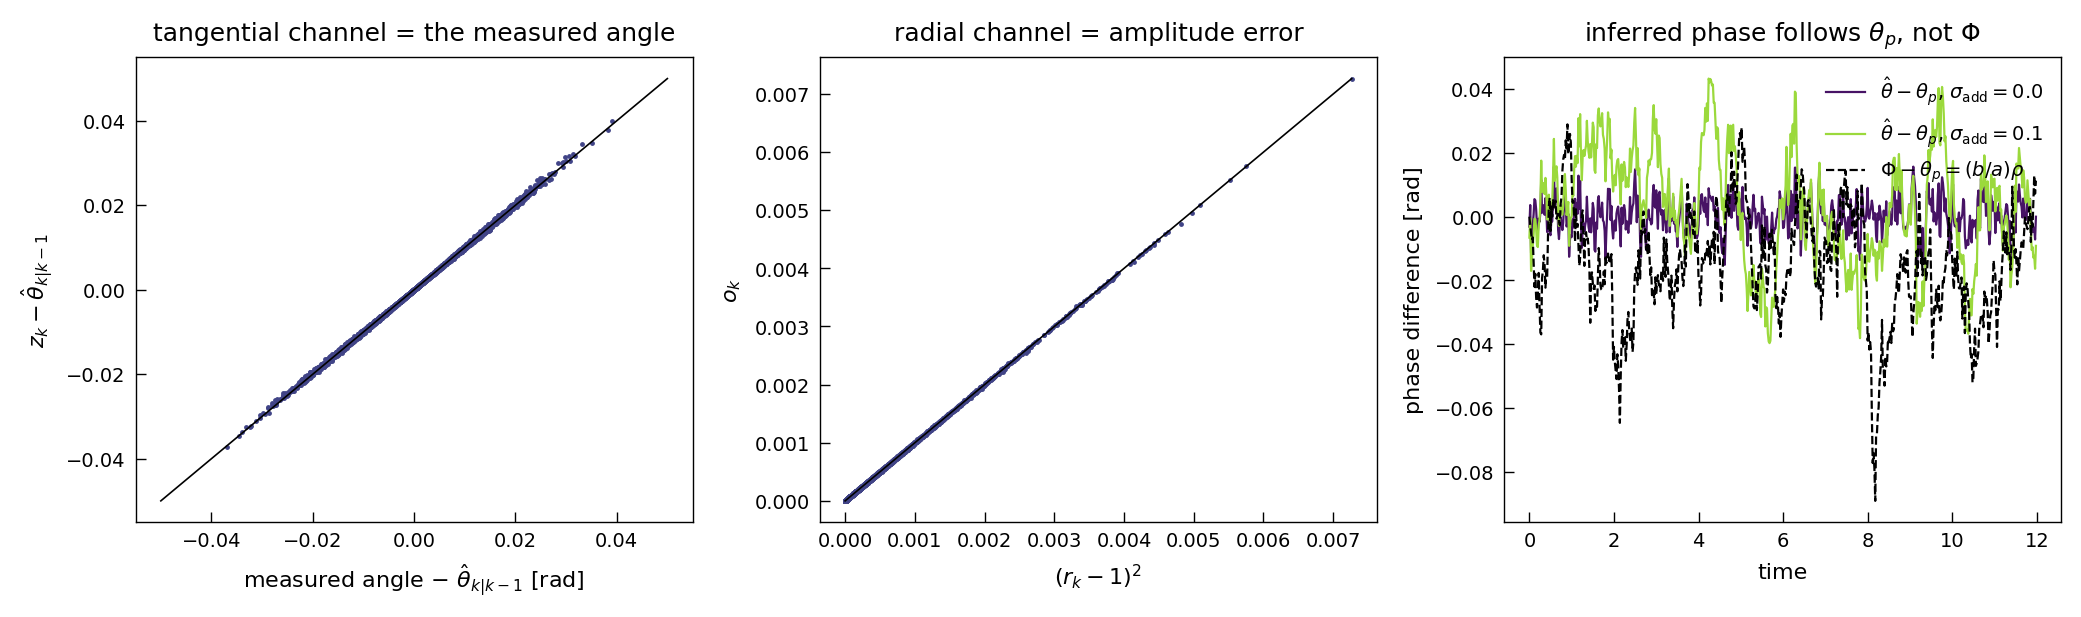

              R_map  tangential    radial  half_sum  rmse_to_theta_p  rmse_to_Phi
sigma_add                                                                        
0.0       2.487e-04   6.870e-05 4.288e-04 2.487e-04        6.527e-03    2.191e-02
0.1       1.011e-02   1.001e-02 1.021e-02 1.011e-02        1.905e-02    2.919e-02

reference values: radial variance D_x/2a = 5.0e-04, (b/a) sigma_rho = 0.0224 rad


In [4]:
# one realisation of the Figure-2 trajectory, N = 8000 samples at dt_inf = 0.02 (T = 160)
cfg8k = replace(cfg, N_INF_max=8000)
traj = NIS.simulate_ensemble(cfg8k, thin=True)

def channels(tk, yk, row_arrays):
    # Return the pseudo-observation z_k, the radial residual o_k, and the EKF prediction at the MAP.
    param, sp = tuple(row_arrays['param_nat']), tuple(row_arrays['state_priors'])
    _, _, thk1, _, _, Hk, ck = FastPhaseEM.ekf_freeze_fast(param, (tk, yk), sp)
    resid = yk - ck
    zk = np.sum(Hk * resid, axis=1)
    ok = np.sum(resid**2, axis=1) - zk**2
    return zk, ok, thk1

summary = []
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.2))
for j, sig in enumerate((0.0, 0.1)):
    tk, yk, th_true, Phi_true = NIS.make_window(traj, cfg8k, sig, 8000, 0, NIS.noise_seed_for(cfg8k, sig, 0))
    row, arr = NIS.fit_window(tk, yk, th_true, Phi_true, cfg8k, want_cov=False, keep_arrays=True)
    zk, ok, thk1 = channels(tk, yk, arr)
    rk = np.hypot(yk[:, 0], yk[:, 1])
    psi = np.arctan2(yk[:, 1], yk[:, 0])
    delta = np.angle(np.exp(1j * (psi - thk1)))
    tang = np.mean((zk - arr['thetakN'])**2 + arr['PkN'])            # E[(z - theta)^2]
    summary.append(dict(sigma_add=sig, R_map=row['R_map'], tangential=tang, radial=ok.mean(),
                        half_sum=0.5 * (tang + ok.mean()),
                        rmse_to_theta_p=row['rmse_geo'], rmse_to_Phi=row['rmse_Phi']))
    if j == 0:
        axs[0].plot(delta, zk - thk1, '.', ms=1.5, color=C['data'])
        axs[0].plot([-0.05, 0.05], [-0.05, 0.05], 'k-', lw=0.6)
        fs.style_axes(axs[0], r'measured angle $-\ \hat\theta_{k|k-1}$ [rad]', r'$z_k-\hat\theta_{k|k-1}$')
        axs[0].set_title(r'tangential channel = the measured angle')
        axs[1].plot((rk - 1)**2, ok, '.', ms=1.5, color=C['data'])
        m_ = ((rk - 1)**2).max(); axs[1].plot([0, m_], [0, m_], 'k-', lw=0.6)
        fs.style_axes(axs[1], r'$(r_k-1)^2$', r'$o_k$'); axs[1].set_title('radial channel = amplitude error')
    ax = axs[2]
    ax.plot(tk[:600], (arr['thetakN'] - th_true)[:600], lw=0.8, color=SEQ(2)[j],
            label=fr'$\hat\theta-\theta_p$, $\sigma_{{\rm add}}={sig}$')
ax.plot(tk[:600], (Phi_true - th_true)[:600], lw=0.8, color='k', ls='--', label=r'$\Phi-\theta_p=(b/a)\rho$')
fs.style_axes(ax, 'time', 'phase difference [rad]'); ax.legend(loc='upper right', fontsize=7)
ax.set_title(r'inferred phase follows $\theta_p$, not $\Phi$')
fig.tight_layout(); plt.show()

S2 = pd.DataFrame(summary).set_index('sigma_add')
print(S2.to_string(float_format=lambda v: f'{v:.3e}'))
print(f"\nreference values: radial variance D_x/2a = {sig_rho2:.1e}, (b/a) sigma_rho = {b/a*np.sqrt(sig_rho2):.4f} rad")
assert np.allclose(S2.R_map, S2.half_sum, rtol=0.02)   # R really is the average of the two channels

**What the numbers say.** At $\sigma_{\rm add}=0$ the measured angle *is* the true $\theta_p$, so the tangential residual is tiny. The radial channel, however, carries the full amplitude variance $D_x/2a=5\times10^{-4}$. The EM averages the two, $R_{\rm map}\approx\tfrac12(\text{tang}+\text{radial})\approx D_x/4a$. The phase filter therefore believes the angle is corrupted by noise of variance $\approx2.5\times10^{-4}$ that does not exist. It smooths away real short-lag phase motion and reports a $D$ that is too small (§5).

The smoothed phase stays within $\sim0.01$ rad of $\theta_p$, while its distance to $\Phi$ is $\approx(b/a)\sigma_\rho$. The algorithm infers the projection phase, as the supplement argues.

## 3 · Information flow when the model is correct (Example 1b data)

Before looking at misspecification we need to know where the information comes from when everything is right.

### 3a · The spectrum of the tangential increments
Take increments of the tangential channel, $d_k=z_k-z_{k-1}=\omega\Delta t+\varepsilon_k+\xi_k-\xi_{k-1}$. Under the model this is a stationary MA(1) process with spectral density (per sample, $\lambda\in[0,\pi]$ in rad/sample)
$$
S_{\rm m}(\lambda)=2D\Delta t+2R\,(1-\cos\lambda)\;\approx\;2D\Delta t+R\lambda^2 .
$$
* **Low frequencies** carry the diffusion: $S_{\rm m}\to 2D\Delta t$.
* **High frequencies** carry the noise: $S_{\rm m}\to 4R$ at $\lambda=\pi$.
* The crossover is at $\lambda^\ast=\sqrt{2D\Delta t/R}=\sqrt{2/\kappa}$ rad/sample, i.e. at a correlation length of $1/\lambda^\ast=\sqrt{\kappa/2}$ samples, or a time lag
$$\tau^\ast=\Delta t\sqrt{\kappa/2}=\sqrt{R\Delta t/2D}.$$
  (The naive MSD crossover $2D\tau=2R$, i.e. $\tau=R/D$, is longer by $\sqrt{2\kappa}$. Averaging the $\sqrt\kappa$ samples inside a window beats the noise down to $R/\sqrt\kappa$, so the displacement only has to beat that, not $R$.)

The key dimensionless group is the **noise-to-diffusion ratio per step**
$$
\kappa=\frac{R}{D\Delta t}.
$$
When $\kappa\ll1$ every increment informs $D$. When $\kappa\gg1$ only lags $\gtrsim\tau^\ast$ do, and there are about $N/\sqrt\kappa$ effectively independent pieces of information. The two parameters are distinguished only by *where in frequency* their influence lies. $D$ and $R$ are separable only because one is flat and the other grows as $\lambda^2$.

### 3b · Fisher information from the spectrum (Whittle)
For a stationary Gaussian sequence the Fisher information per sample is
$$
\mathcal I_{ij}=\frac{1}{2\pi}\int_0^\pi\partial_i\ln S_{\rm m}\,\partial_j\ln S_{\rm m}\,d\lambda,
\qquad
\partial_{\ln D}\ln S_{\rm m}=\frac{2D\Delta t}{S_{\rm m}},\quad
\partial_{\ln R}\ln S_{\rm m}=\frac{2R(1-\cos\lambda)}{S_{\rm m}} .
$$
The radial channel adds $\tfrac12$ per sample to $\mathcal I_{\ln R,\ln R}$, because each $o_k$ is the square of an independent $\mathcal N(0,R)$ draw. The frequency is the mean increment, so $\mathrm{Var}(\omega)=S_{\rm m}(0)/(N\Delta t^2)=2D/T$ with $T=N\Delta t$. **Its error bar is set by $D$.** A biased $D$ propagates directly into a mis-sized $\sigma_\omega$.

Limits:
* $\kappa\to0$: $\mathcal I_{\ln D\ln D}\to\tfrac12$, so $\mathrm{Var}(\ln D)\to 2/N$ (supplement eq. *variance*).
* $\kappa\gg1$: $\mathrm{Var}(\ln D)\to4\sqrt{2\kappa}/N$ (from $\mathcal I_{\ln D\ln D}\to\tfrac{1}{8}\sqrt{2/\kappa}$), i.e. $\propto\sqrt\kappa/N$. The record holds $N/\sqrt\kappa$ independent pieces of information on $D$, not $N/\kappa$. §3c checks this: at $\kappa=8$, $N=3000$ the formula gives $0.073$.

The integrand of $\mathcal I_{\ln D\ln D}$ is literally *the information density over frequency*. Plotting it shows where the algorithm looks.

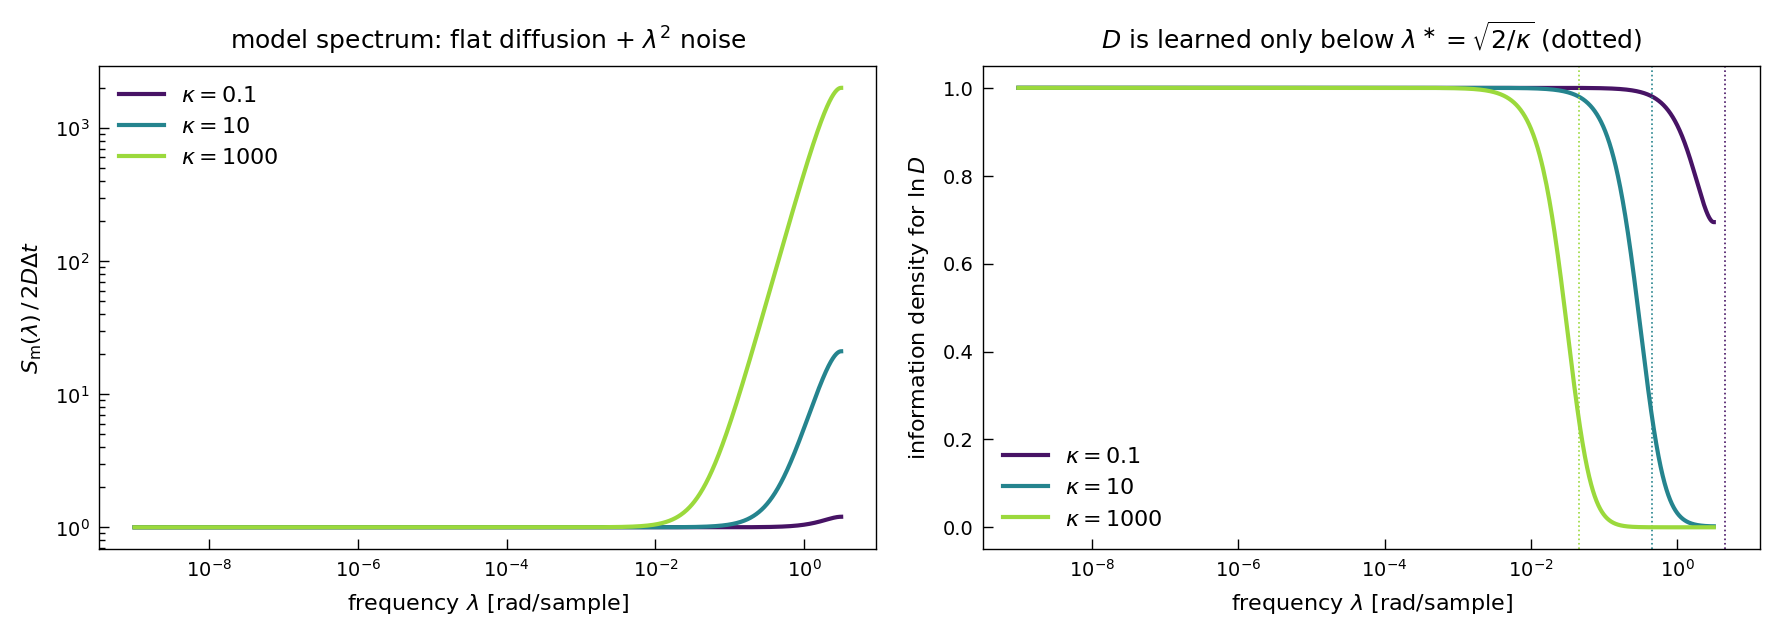

In [5]:
# frequency grid: log-spaced at low lambda (diffusion lives there) + linear up to pi
LAM = np.concatenate([np.geomspace(1e-9, 1e-2, 3000, endpoint=False), np.linspace(1e-2, np.pi, 4000)])


def S_model(lam: np.ndarray, D: float, R: float, dt: float) -> np.ndarray:
    # Model spectral density of tangential increments, per sample [rad^2].
    return 2 * D * dt + 2 * R * (1 - np.cos(lam))


def whittle_fisher(D: float, R: float, dt: float, N: int, radial: bool = True) -> dict:
    # Asymptotic posterior sds of (ln D, ln R) and omega for the inference model (Whittle).
    #
    # Parameters
    # ----------
    # D : phase diffusivity [rad^2/time];  R : noise variance [rad^2 = length^2 on the unit circle]
    # dt : sampling interval [time];  N : number of samples
    # radial : include the radial channel (2D measurement, Example 1b) or not (scalar, Example 1a)
    S = S_model(LAM, D, R, dt)
    g = np.vstack([2 * D * dt / S, 2 * R * (1 - np.cos(LAM)) / S])
    I = np.trapezoid(g[:, None, :] * g[None, :, :], LAM, axis=-1) / (2 * np.pi)
    if radial:
        I[1, 1] += 0.5
    Cov = np.linalg.inv(N * I)
    return dict(sd_lnD=np.sqrt(Cov[0, 0]), sd_lnR=np.sqrt(Cov[1, 1]),
                corr=Cov[0, 1] / np.sqrt(Cov[0, 0] * Cov[1, 1]),
                sd_omega=np.sqrt(2 * D / (N * dt)), cov=Cov)


# information density over frequency for three values of kappa
fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
D0, dt0 = 0.05, 0.05
for kap, col in zip((0.1, 10, 1000), SEQ(3)):
    R0 = kap * D0 * dt0
    S = S_model(LAM, D0, R0, dt0)
    axs[0].loglog(LAM, S / (2 * D0 * dt0), color=col, label=fr'$\kappa={kap:g}$')
    axs[1].semilogx(LAM, (2 * D0 * dt0 / S)**2, color=col, label=fr'$\kappa={kap:g}$')
    axs[1].axvline(np.sqrt(2 / kap), color=col, lw=0.6, ls=':')
fs.style_axes(axs[0], r'frequency $\lambda$ [rad/sample]', r'$S_{\rm m}(\lambda)\,/\,2D\Delta t$')
axs[0].set_title('model spectrum: flat diffusion + $\\lambda^2$ noise'); axs[0].legend()
fs.style_axes(axs[1], r'frequency $\lambda$ [rad/sample]', r'information density for $\ln D$')
axs[1].set_title(r'$D$ is learned only below $\lambda^\ast=\sqrt{2/\kappa}$ (dotted)'); axs[1].legend()
fig.tight_layout(); plt.show()

### 3c · Check: unbiased estimates and calibrated error bars
We simulate data **from the inference model itself** (`SLPI.simulate_data`) at a low and a high $\kappa$, and fit each replicate with the sweep pipeline (`NIS.fit_window`). We compare:
* the replicate scatter of the MAPs (the honest error bar);
* the mean Laplace sd (the claimed error bar);
* the Whittle prediction above.

The **oracle** estimate $\hat D_{\rm oracle}=\sum_k(\Delta\theta_k-\hat\omega\Delta t)^2/2(N-1)\Delta t$ uses the *true* phases. Comparing to it separates "what this realisation's phase actually did" from "what the inference added". That is the $\mathcal I_{\rm comp}$ vs $\mathcal I_{\rm comp}-\mathcal I_{\rm miss}$ split of the Louis identity.

In [6]:
omega0, D0, dt0, N0, n_rep = 1.0, 0.05, 0.05, 3000, 16
cfg_1b = replace(cfg, N_INF_max=N0)
res = []
t_start = time.time()
for kap in (0.04, 8.0):
    R0 = kap * D0 * dt0
    for m in range(n_rep):
        rng = np.random.default_rng(1000 + m)
        tk, thk, yk = SLPI.simulate_data((omega0, D0, R0), N0, dt0, rng, (0.0, 0.1))
        row = NIS.fit_window(tk, yk, thk, thk, cfg_1b)
        dth = np.diff(thk)
        w_or = (thk[-1] - thk[0]) / (tk[-1] - tk[0])
        res.append(dict(kappa=kap, rep=m, omega=row['omega_map'], lnD=np.log(row['D_map']),
                        lnR=np.log(row['R_map']), sd_omega=row['omega_std'], sd_lnD=row['lnD_std'],
                        sd_lnR=row['lnR_std'], acf1=row['acf1'],
                        lnD_oracle=np.log(np.sum((dth - w_or * dt0)**2) / (2 * (N0 - 1) * dt0))))
res = pd.DataFrame(res)
print(f"{len(res)} fits in {time.time() - t_start:.0f} s\n")

tab = []
for kap, g in res.groupby('kappa'):
    R0 = kap * D0 * dt0
    wf, wf1a = whittle_fisher(D0, R0, dt0, N0), whittle_fisher(D0, R0, dt0, N0, radial=False)
    tab.append({'kappa': kap,
                'ln(D/D_true) mean': (g.lnD - np.log(D0)).mean(),
                'sd lnD: replicates': g.lnD.std(ddof=1), 'sd lnD: Laplace': g.sd_lnD.mean(),
                'sd lnD: Whittle': wf['sd_lnD'], 'sd lnD: oracle(true theta)': g.lnD_oracle.std(ddof=1),
                'sd omega: replicates': g.omega.std(ddof=1), 'sd omega: Laplace': g.sd_omega.mean(),
                'sd omega: sqrt(2D/T)': wf['sd_omega'],
                'corr(lnD,lnR) 1b (2D)': wf['corr'], 'corr(lnD,lnR) 1a (scalar)': wf1a['corr'],
                'innovation acf1': g.acf1.mean()})
tab = pd.DataFrame(tab).set_index('kappa').T
print(tab.to_string(float_format=lambda v: f'{v:+.4f}'))

# bias in units of the standard error of the replicate mean (realised-path effects included via the oracle)
for kap, g in res.groupby('kappa'):
    z = (g.lnD - g.lnD_oracle).mean() / ((g.lnD - g.lnD_oracle).std(ddof=1) / np.sqrt(n_rep))
    print(f"kappa = {kap:g}: mean(ln D_map - ln D_oracle) = {(g.lnD - g.lnD_oracle).mean():+.4f}  (z = {z:+.1f})")
    assert np.all(np.abs(g.lnD - np.log(D0)) < 4 * g.sd_lnD)

32 fits in 27 s

kappa                         0.04    8.00
ln(D/D_true) mean          -0.0250 -0.0355
sd lnD: replicates         +0.0219 +0.0687
sd lnD: Laplace            +0.0270 +0.0748
sd lnD: Whittle            +0.0268 +0.0744
sd lnD: oracle(true theta) +0.0189 +0.0189
sd omega: replicates       +0.0292 +0.0292
sd omega: Laplace          +0.0255 +0.0254
sd omega: sqrt(2D/T)       +0.0258 +0.0258
corr(lnD,lnR) 1b (2D)      -0.0370 -0.2485
corr(lnD,lnR) 1a (scalar)  -0.8059 -0.3971
innovation acf1            +0.0096 +0.0025
kappa = 0.04: mean(ln D_map - ln D_oracle) = -0.0142  (z = -6.3)
kappa = 8: mean(ln D_map - ln D_oracle) = -0.0247  (z = -1.3)


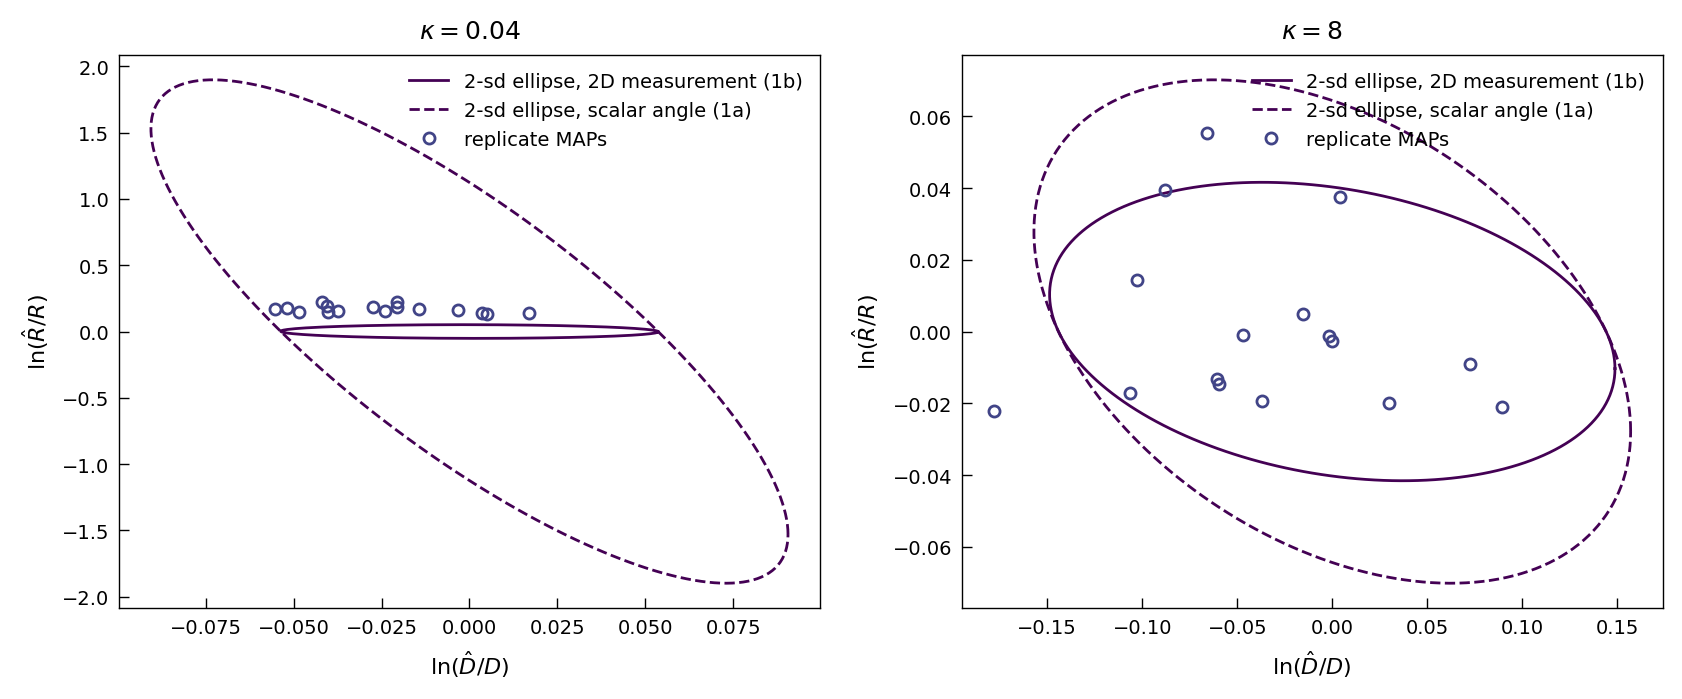

In [7]:
# D-R posterior geometry: Whittle ellipses (lines) vs replicate MAPs (dots)
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.6))
th = np.linspace(0, 2 * np.pi, 200)
for ax, (kap, g) in zip(axs, res.groupby('kappa')):
    R0 = kap * D0 * dt0
    for radial, ls, lab in ((True, '-', '2D measurement (1b)'), (False, '--', 'scalar angle (1a)')):
        Cv = whittle_fisher(D0, R0, dt0, N0, radial=radial)['cov']
        L = np.linalg.cholesky(Cv)
        e = 2 * L @ np.vstack([np.cos(th), np.sin(th)])
        ax.plot(e[0], e[1], ls, color=C['theory'], lw=1, label=f'2-sd ellipse, {lab}')
    ax.plot(g.lnD - np.log(D0), g.lnR - np.log(R0), 'o', ms=4, mfc='none', color=C['data'], label='replicate MAPs')
    fs.style_axes(ax, r'$\ln(\hat D/D)$', r'$\ln(\hat R/R)$')
    ax.set_title(fr'$\kappa={kap:g}$'); ax.legend(loc='upper right', fontsize=7)
fig.tight_layout(); plt.show()

**Take-aways from §3.**
* With the correct model, the Laplace sd matches the Whittle prediction, and both match the replicate scatter within the $\approx18\,\%$ sampling error of a 16-replicate sd. For $\omega$ it matches $\sqrt{2D/T}$.
* The estimates are *not* exactly unbiased: $\ln\hat D$ sits $\approx1.5\,\%$ below the oracle and $\hat R$ sits $\approx15\,\%$ high at $\kappa=0.04$ (dots offset from the ellipse centre). This bias comes from the EKF itself; see §3d.
* Raising $\kappa$ inflates $\mathrm{sd}(\ln D)$ well beyond the $\sqrt{2/N}$ oracle: information is lost to the noise ($\mathcal I_{\rm miss}$). It does not touch $\mathrm{sd}(\omega)$.
* For a *scalar* angle measurement (dashed, Example 1a), $D$ and $R$ are strongly anti-correlated, most strongly at *low* $\kappa$: $\mathrm{corr}\to-\sqrt{2/3}=-0.82$ as $\kappa\to0$, because $\partial_{\ln R}\ln S_{\rm m}\propto1-\cos\lambda$ is then nearly collinear with the flat $\partial_{\ln D}\ln S_{\rm m}$ (table: $-0.81$ at $\kappa=0.04$, $-0.40$ at $\kappa=8$). The 2D measurement (solid, 1b) pins $R$ through the radial channel and nearly removes the correlation. **That decoupling is exactly what turns harmful once the radial residual is amplitude fluctuation rather than noise.**
* Both $\kappa$ columns use the same 16 phase paths (seeds 1000–1015) with different noise, which is why the oracle and $\omega$ rows are identical. Those 16 paths happen to have a realised diffusivity $1.1\,\%$ below $D_0$ (a $2.3\sigma$ fluctuation of the oracle mean), so the oracle-relative row, not the $\ln(D/D_{\rm true})$ row, measures the EKF bias.


### 3d · The EKF's own bias: curvature leaks into the radial channel
Expand the measurement about the prediction, with $\delta_k=\theta_k-\hat\theta_{k\mid k-1}$ and $\mathbf h''=-\mathbf h$, $\mathbf h'''=-\mathbf H$:
$$
\mathbf h(\theta_k)=\mathbf h(\hat\theta)+\mathbf H_k\delta_k-\tfrac12\,\mathbf h(\hat\theta)\,\delta_k^2-\tfrac16\,\mathbf H_k\,\delta_k^3+\dots
$$
* The **second-order term points along $\mathbf h$, i.e. radially**. It never touches the phase channel but adds to the radial residual, $o_k\approx(n^\parallel_k-\delta_k^2/2)^2$. Because $R$ is shared, $\hat R\approx R+\tfrac38P_{k\mid k-1}^2$ to leading order. This is the *same mechanism* by which SL amplitude fluctuations bias $R$, only here the "amplitude" is the chord of the circle.
* The **third-order term** compresses the tangential innovation, $\sin\delta\approx\delta-\delta^3/6$. Together with the inflated $R$ this lowers $\hat D$ by a fraction of order $2D\Delta t$. The prefactor is not derived here; the scan below measures it ($-2.3$ to $-2.5$ at $\kappa=0.04$, $-1.9$ to $-2.5$ at $\kappa=1$), so $-2$ is a round number, and the dashed line in the figure is an empirical fit.

The drift $\omega\Delta t$ does not appear anywhere, because it is part of the prediction. The bias is controlled by the **prediction variance** $P_{k\mid k-1}\approx2D\Delta t+P_{k-1\mid k-1}$:
$$
\text{unbiased }\hat R:\ 3P_{k\mid k-1}^2/8R\ll1,\qquad
\text{unbiased }\hat D:\ 2D\Delta t\ll1\ \ (\text{bias}\approx-(2\text{–}2.5)\times2D\Delta t\text{ in }\ln D).
$$
This replaces the supplement's "avoiding bias" condition $(\omega\Delta t)^2\ll\sqrt R$. Supplement case 2 violates that condition by $\sim200\times$ ($\omega\Delta t=2.16$, $\sqrt R\approx0.022$), yet it is reproduced within its Laplace error bar in §6. In `SPNM_Performance` the conditions appear as C1 $\sqrt{2D\Delta t}\ll1$, C2 $(2D\Delta t\,R)^{1/4}\ll1$ and C3 $(\omega\Delta t)^2/\sqrt R\ll1$ with threshold $\varepsilon=0.2$: C1 is the $2D\Delta t$ condition above, C2 equals $\sqrt{P_{k|k-1}}$ at the steady state $P\approx\sqrt{QR}$ ($Q\ll R$), and C3 is the one superseded here. `StuartLandauInference.ipynb` evaluates all three for its cases. For all Stuart–Landau runs below, $2D\Delta t\approx3\times10^{-5}$, so this bias is negligible there.

72 fits in 17 s
             P_over_sqrtR  pred_lnR    dlnD  dlnD_se    dlnR  dlnR_se
kappa Q                                                              
0.04  0.002       +0.3224   +0.0382 -0.0078  +0.0028 +0.0449  +0.0084
      0.010       +0.7210   +0.1781 -0.0254  +0.0026 +0.3147  +0.0083
      0.040       +1.4420   +0.5765 -0.0923  +0.0030 +0.9045  +0.0080
1.00  0.002       +0.0864   +0.0028 -0.0013  +0.0131 -0.0199  +0.0078
      0.010       +0.1932   +0.0139 -0.0251  +0.0078 +0.0140  +0.0058
      0.040       +0.3864   +0.0545 -0.0738  +0.0117 +0.0741  +0.0065


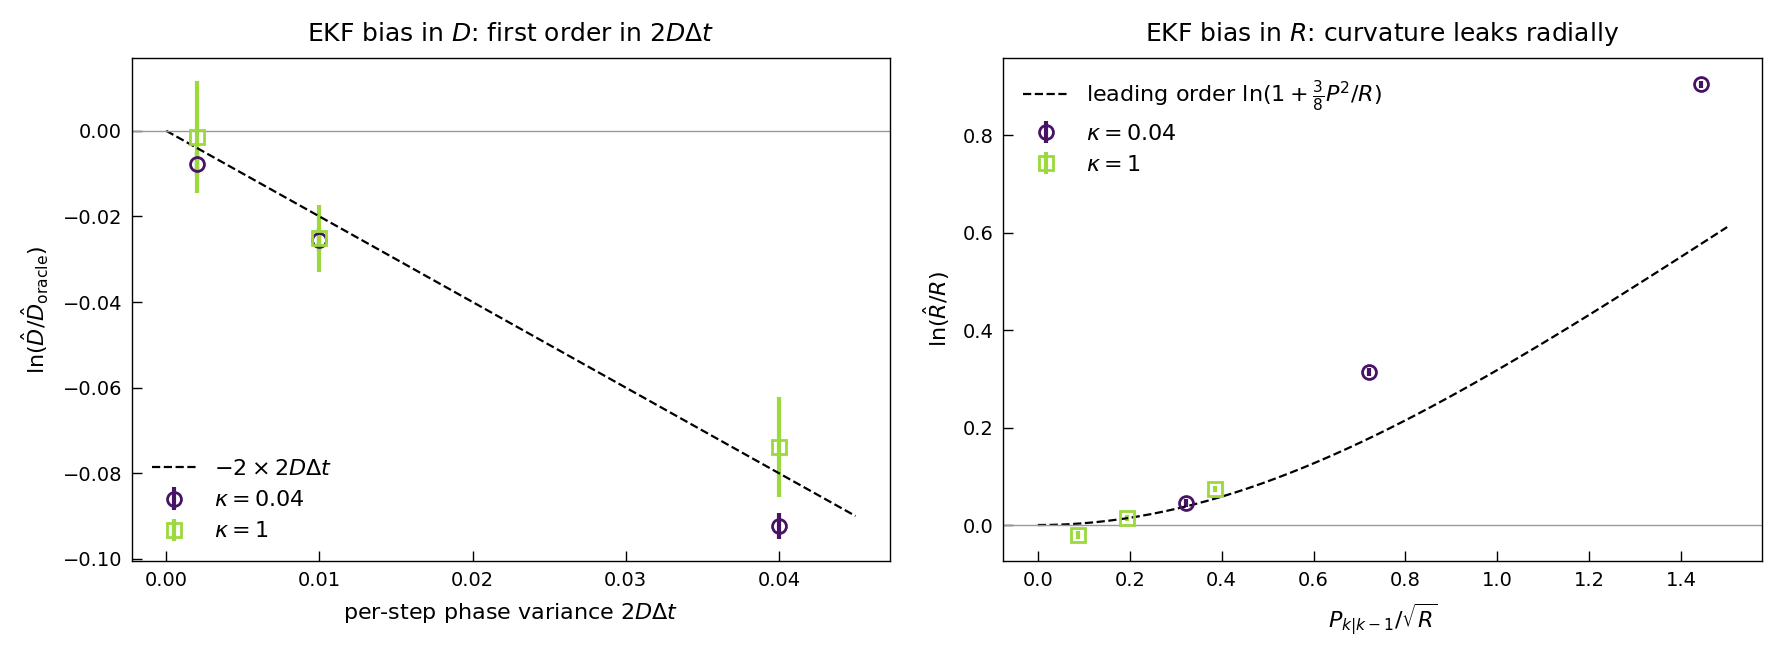

In [8]:
# scan the per-step phase variance Q = 2 D dt at two noise ratios kappa (12 replicates each)
scan = []
t_start = time.time()
for kap in (0.04, 1.0):
    for D_s in (0.02, 0.1, 0.4):
        R_s, Q_s = kap * D_s * dt0, 2 * D_s * dt0
        P_s = Q_s / 2 + np.sqrt(Q_s**2 / 4 + Q_s * R_s)               # steady-state P_{k|k-1}
        for m in range(12):
            rng = np.random.default_rng(1000 + m)
            tk, thk, yk = SLPI.simulate_data((omega0, D_s, R_s), N0, dt0, rng, (0.0, 0.1))
            row = NIS.fit_window(tk, yk, thk, thk, cfg_1b, want_cov=False)
            dth = np.diff(thk); w_or = (thk[-1] - thk[0]) / (tk[-1] - tk[0])
            D_or = np.sum((dth - w_or * dt0)**2) / (2 * (N0 - 1) * dt0)
            scan.append(dict(kappa=kap, Q=Q_s, P_over_sqrtR=P_s / np.sqrt(R_s),
                             pred_lnR=np.log(1 + 3 * P_s**2 / (8 * R_s)),
                             dlnD=np.log(row['D_map'] / D_or), dlnR=np.log(row['R_map'] / R_s)))
scan = pd.DataFrame(scan)
sg = scan.groupby(['kappa', 'Q']).agg(P_over_sqrtR=('P_over_sqrtR', 'first'), pred_lnR=('pred_lnR', 'first'),
                                      dlnD=('dlnD', 'mean'), dlnD_se=('dlnD', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
                                      dlnR=('dlnR', 'mean'), dlnR_se=('dlnR', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
print(f"{len(scan)} fits in {time.time() - t_start:.0f} s")
print(sg.to_string(float_format=lambda v: f'{v:+.4f}'))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for (kap, g), col, mk in zip(sg.groupby(level=0), SEQ(2), ('o', 's')):
    Qv = g.index.get_level_values('Q')
    axs[0].errorbar(Qv, g.dlnD, g.dlnD_se, fmt=mk, color=col, ms=5, mfc='none', label=fr'$\kappa={kap:g}$')
    axs[1].errorbar(g.P_over_sqrtR, g.dlnR, g.dlnR_se, fmt=mk, color=col, ms=5, mfc='none', label=fr'$\kappa={kap:g}$')
qq = np.linspace(0, 0.045, 50)
axs[0].plot(qq, -2 * qq, 'k--', lw=0.8, label=r'$-2\times2D\Delta t$')
xx = np.linspace(0, 1.5, 50)
axs[1].plot(xx, np.log(1 + 3 * xx**2 / 8), 'k--', lw=0.8, label=r'leading order $\ln(1+\frac{3}{8}P^2/R)$')
for ax in axs: ax.axhline(0, color='0.6', lw=0.5)
fs.style_axes(axs[0], r'per-step phase variance $2D\Delta t$', r'$\ln(\hat D/\hat D_{\rm oracle})$')
axs[0].set_title('EKF bias in $D$: first order in $2D\\Delta t$'); axs[0].legend()
fs.style_axes(axs[1], r'$P_{k|k-1}/\sqrt{R}$', r'$\ln(\hat R/R)$')
axs[1].set_title('EKF bias in $R$: curvature leaks radially'); axs[1].legend()
fig.tight_layout(); plt.show()

## 4 · Misspecification: what the Stuart–Landau data really look like to the filter

### 4a · True spectra of the two channels
**Tangential channel.** $z_k\approx\psi_k=\theta_p(t_k)+n^{\perp}_k$, with $n^\perp_k\sim\mathcal N(0,\sigma_{\rm add}^2)$. The angular velocity is $\dot\theta_p=1+2b\rho+\sqrt{2D_x}\,\xi_\varphi$, so an increment contains a white part plus the integral of an OU process. Its autocovariance has three parts:
$$
\gamma(0)=2D_x\Delta t+4b^2\sigma_\rho^2\,2\Big[\frac{\Delta t}{2a}-\frac{1-c}{(2a)^2}\Big]+2\sigma_{\rm add}^2,\qquad
\gamma(m\ge1)=4b^2\sigma_\rho^2\,\frac{c^{\,m-1}(1-c)^2}{(2a)^2}-\sigma_{\rm add}^2\,\delta_{m1},
\qquad c=e^{-2a\Delta t}.
$$
Summing the geometric series gives a closed form:
$$
S_{\rm true}(\lambda)=\gamma_0^{\rm OU}+2B\,\mathrm{Re}\frac{e^{i\lambda}}{1-c\,e^{i\lambda}}+2\sigma_{\rm add}^2(1-\cos\lambda),
\qquad S_{\rm true}(0)=2D_{\rm eff}\Delta t .
$$
* **The lag-one correlation of the coloured part is positive.** It looks like the *opposite* of measurement noise, which is the spectral version of the negative MSD intercept in §1b.
* **The model can only add a positive $\lambda^2$ term.**

**Radial channel.** $o_k\approx(\rho_k+n^\parallel_k)^2$, so the radial residual has variance $\sigma_\rho^2+\sigma_{\rm add}^2$. The model treats it as white $\mathcal N(0,R)$. For a white Gaussian model the expected log-likelihood depends only on this variance, so the colour of $\rho$ does not matter here; its *size* does.

In [9]:
def S_true(lam: np.ndarray, sigma_add: float, dt: float, a: float, b: float, Dx: float) -> np.ndarray:
    # Exact spectral density of increments of the measured SL angle (linearised), per sample [rad^2].
    #
    # Parameters
    # ----------
    # sigma_add : injected isotropic Cartesian noise sd [length]
    # dt : sampling interval [time];  a, b, Dx : SL parameters
    c = np.exp(-2 * a * dt)
    k = (2 * b)**2 * Dx / (2 * a)                 # (2b)^2 sigma_rho^2
    g0 = 2 * Dx * dt + k * 2 * (dt / (2 * a) - (1 - c) / (2 * a)**2)
    B = k * (1 - c)**2 / (2 * a)**2
    z = np.exp(1j * lam)
    return g0 + 2 * B * np.real(z / (1 - c * z)) + 2 * sigma_add**2 * (1 - np.cos(lam))


# consistency checks: zero-frequency limit and the one-step variance against the stationary MSD formula
for dt_c in (0.02, 1.0):
    s0 = S_true(np.array([1e-12]), 0.0, dt_c, a, b, Dx)[0]
    var1 = np.trapezoid(S_true(LAM, 0.0, dt_c, a, b, Dx), LAM) / np.pi
    print(f"dt = {dt_c}:  S(0)/(2 D_eff dt) = {s0 / (2 * D_eff * dt_c):.6f},   "
          f"Var(one increment) / MSD_theta_p(dt) = {var1 / msd_theta_p(dt_c, a, b, Dx):.6f}")
    assert abs(s0 / (2 * D_eff * dt_c) - 1) < 1e-9
    assert abs(var1 / msd_theta_p(dt_c, a, b, Dx) - 1) < 1e-3

dt = 0.02:  S(0)/(2 D_eff dt) = 1.000000,   Var(one increment) / MSD_theta_p(dt) = 1.000000
dt = 1.0:  S(0)/(2 D_eff dt) = 1.000000,   Var(one increment) / MSD_theta_p(dt) = 1.000000


### 4b · The best a random walk + white noise can do
For each noise level we find the model spectrum closest to the truth (§5 explains the criterion) and overlay the two. In the time domain the same comparison is
$$
\text{truth: } \mathrm{MSD}(\tau)=2D_{\rm eff}\tau-2\tfrac{b^2}{a^2}\sigma_\rho^2(1-e^{-2a\tau})+2\sigma_{\rm add}^2
\qquad\text{vs.}\qquad
\text{model: } 2D\tau+2R .
$$

## 5 · Predicting the fitted parameters without fitting: the KL projection

When the model is wrong, maximum likelihood still converges as $N\to\infty$, but not to a "true value", because there isn't one. It converges to the **pseudo-true parameter**
$$
\lambda^\ast=\arg\min_\lambda\ \mathrm{KL}\big(p_{\rm true}\,\big\Vert\,p_\lambda\big),
$$
the member of the model family closest to the data-generating process (White 1982). For stationary Gaussian sequences the large-$N$ log-likelihood per sample is the Whittle functional. Summing both channels:
$$
\lambda^\ast=\arg\min_{D,R}\;
\underbrace{\frac1\pi\int_0^\pi\Big[\ln S_{\rm m}(\lambda;D,R)+\frac{S_{\rm true}(\lambda)}{S_{\rm m}(\lambda;D,R)}\Big]d\lambda}_{\text{tangential channel}}
\;+\;\underbrace{\ln R+\frac{\sigma_\rho^2+\sigma_{\rm add}^2}{R}}_{\text{radial channel (shared }R)} .
$$
The prior's influence vanishes as $N\to\infty$, so $\lambda^\ast$ is the large-$N$ limit of the EM-MAP. Two **ablations** separate the two mechanisms:
* **separate $R$** (drop the radial term): only the coloured-phase mismatch remains;
* **$b=0$** (no shear): the tangential channel is an exact random walk with $D_x$, so only the shared-$R$ mismatch remains.

Analytic checks, asserted below:
1. $b=0$, separate $R$, $\sigma_{\rm add}>0$: the model is exact, so $D^\ast=D_x$ and $R^\ast=\sigma_{\rm add}^2$.
2. $\sigma_{\rm add}\to\infty$: only $\lambda\to0$ is resolved, so $D^\ast\to S_{\rm true}(0)/2\Delta t=D_{\rm eff}$.
3. $\Delta t\gg\tau_r$ with separate $R$: $D^\ast$ approaches the chord diffusivity $\mathrm{MSD}_{\theta_p}(\Delta t)/2\Delta t=D_{\rm eff}-(b/a)^2\sigma_\rho^2/\Delta t$.

In [10]:
def kl_projection(sigma_add: float, dt: float, a: float = a, b: float = b, Dx: float = Dx,
                  shared_R: bool = True) -> dict:
    # Pseudo-true (D*, R*) of the random-walk + white-noise model for SL data (Whittle KL minimiser).
    #
    # Returns dict with D [rad^2/time] and R [length^2].
    S = S_true(LAM, sigma_add, dt, a, b, Dx)
    V_rad = Dx / (2 * a) + sigma_add**2

    def objective(p):
        D, R = np.exp(p)
        Sm = S_model(LAM, D, R, dt)
        f = np.trapezoid(np.log(Sm) + S / Sm, LAM) / np.pi
        return f + (np.log(R) + V_rad / R if shared_R else 0.0)

    x0 = np.log([Dx * (1 + b**2 / a**2), V_rad])
    opt = minimize(objective, x0, method='Nelder-Mead',
                   options=dict(xatol=1e-10, fatol=1e-16, maxiter=8000))
    D, R = np.exp(opt.x)
    return dict(D=D, R=R)


# analytic limits
k1 = kl_projection(0.05, dt_inf, b=0.0, shared_R=False)
k2 = kl_projection(10.0, dt_inf)
k3 = kl_projection(0.0, 20.0, shared_R=False)
chord = msd_theta_p(20.0, a, b, Dx) / (2 * 20.0)
print(f"(1) b=0, separate R: D*/D_x = {k1['D']/Dx:.6f},  R*/sigma^2 = {k1['R']/0.05**2:.6f}")
print(f"(2) sigma_add = 10:   D*/D_eff = {k2['D']/D_eff:.5f}")
print(f"(3) dt = 20 tau_r... : D*/chord = {k3['D']/chord:.4f}")
assert abs(k1['D'] / Dx - 1) < 1e-3 and abs(k1['R'] / 0.05**2 - 1) < 1e-3
assert abs(k2['D'] / D_eff - 1) < 2e-3
assert abs(k3['D'] / chord - 1) < 0.01

(1) b=0, separate R: D*/D_x = 1.000000,  R*/sigma^2 = 1.000000
(2) sigma_add = 10:   D*/D_eff = 0.99976
(3) dt = 20 tau_r... : D*/chord = 1.0000


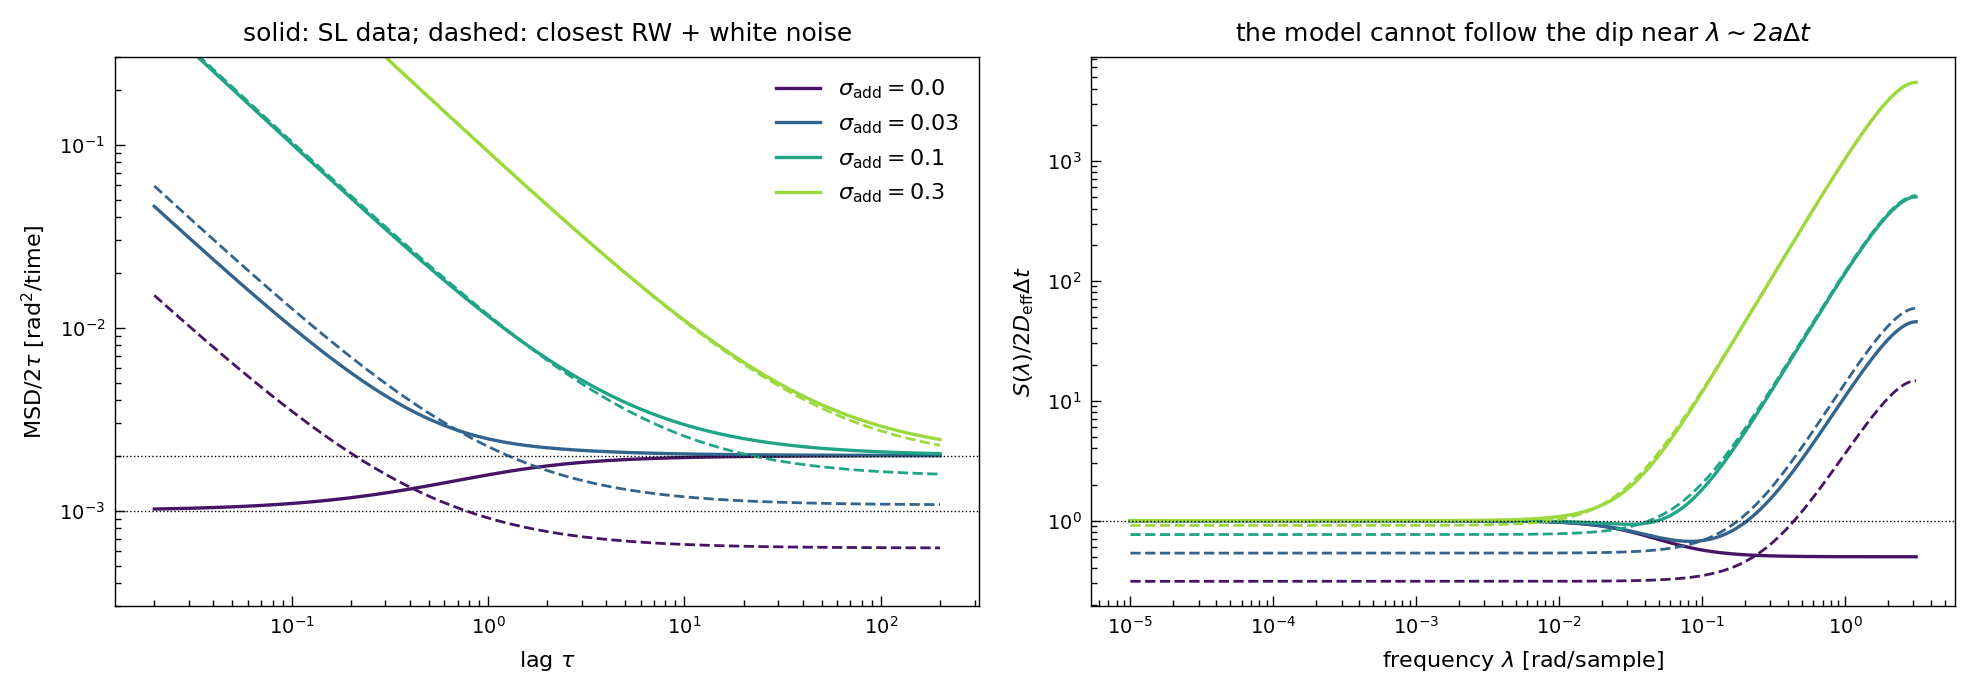

In [11]:
# §4b figure: true vs best-fit model, in lag space and frequency space
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
tau = np.geomspace(dt_inf, 200, 400)
lam_plot = np.geomspace(1e-5, np.pi, 400)
for sig, col in zip((0.0, 0.03, 0.1, 0.3), SEQ(4)):
    kp = kl_projection(sig, dt_inf)
    msd_true = msd_theta_p(tau, a, b, Dx) + 2 * sig**2
    axs[0].loglog(tau, msd_true / (2 * tau), color=col, lw=1.2, label=fr'$\sigma_{{\rm add}}={sig}$')
    axs[0].loglog(tau, (2 * kp['D'] * tau + 2 * kp['R']) / (2 * tau), color=col, lw=1, ls='--')
    axs[1].loglog(lam_plot, S_true(lam_plot, sig, dt_inf, a, b, Dx) / (2 * D_eff * dt_inf), color=col, lw=1.2)
    axs[1].loglog(lam_plot, S_model(lam_plot, kp['D'], kp['R'], dt_inf) / (2 * D_eff * dt_inf), color=col, ls='--', lw=1)
for ax in axs:
    ax.axhline(1 if ax is axs[1] else D_eff, color='k', lw=0.5, ls=':')
axs[0].axhline(Dx, color='k', lw=0.5, ls=':')
axs[0].set_ylim(3e-4, 0.3)
fs.style_axes(axs[0], r'lag $\tau$', r'MSD$/2\tau$ [rad$^2$/time]')
axs[0].set_title('solid: SL data; dashed: closest RW + white noise'); axs[0].legend(loc='upper right')
fs.style_axes(axs[1], r'frequency $\lambda$ [rad/sample]', r'$S(\lambda)/2D_{\rm eff}\Delta t$')
axs[1].set_title('the model cannot follow the dip near $\\lambda\\sim 2a\\Delta t$')
fig.tight_layout(); plt.show()

**Reading the figure.** The solid curves (data) dip *below* $D_{\rm eff}$ at intermediate lags, which is the negative intercept from §1b. The model's curves (dashed) can only bend *up* at short lags, because noise adds $+2R/2\tau$. As $\sigma_{\rm add}$ grows, the true curve is dominated by its own $2\sigma_{\rm add}^2/2\tau$ rise. The dip becomes a small perturbation hidden under the noise, and the best-fit line is pushed out to long lags where $\mathrm{MSD}/2\tau\to D_{\rm eff}$.

This is why **added white noise "regularises" the estimate toward $D_{\rm eff}$.** It moves the information window ($\tau^\ast=\sqrt{R\Delta t/2D}$, §3) past $\tau_r$. In the spectrum: the dip sits at $\lambda\approx2a\Delta t$ and is hidden once $\lambda^\ast=\sqrt{2/\kappa}<2a\Delta t$, i.e. $\tau^\ast>\tau_r$, which here means $\sigma_{\rm add}\gtrsim0.2$. The transition is broad, though: $D^\ast/D_{\rm eff}$ climbs from $0.31$ to $0.95$ over four decades in $R$ (§5 table), so no single crossover value is sharp.

In [12]:
# KL prediction vs the 1872-fit sweep at the largest budget (N = 512000, T = 10240)
big = sweep.query('N_INF == 512000').groupby('sigma_add').agg(
    D_mean=('D_map', 'mean'), D_se=('D_map', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    R_mean=('R_map', 'mean'))
rows = []
for sig, r_ in big.iterrows():
    k_sh, k_sep, k_b0 = kl_projection(sig, dt_inf), kl_projection(sig, dt_inf, shared_R=False), kl_projection(sig, dt_inf, b=0.0)
    rows.append({'sigma_add': sig,
                 'D_map/D_eff (sweep)': r_.D_mean / D_eff, '± se': r_.D_se / D_eff,
                 'D*/D_eff (KL)': k_sh['D'] / D_eff,
                 'rel. diff': r_.D_mean / k_sh['D'] - 1,
                 'R_map (sweep)': r_.R_mean, 'R* (KL)': k_sh['R'],
                 'ablation: separate R': k_sep['D'] / D_eff,
                 'ablation: b=0  (D*/D_x)': k_b0['D'] / Dx})
KL = pd.DataFrame(rows).set_index('sigma_add')
print(KL.to_string(float_format=lambda v: f'{v:.4g}'))
ok = KL.index <= 0.3
assert np.all(np.abs(KL['rel. diff'][ok]) < 0.01), "KL projection should match the sweep to 1% for sigma_add <= 0.3"
assert np.allclose(KL['R_map (sweep)'][ok], KL['R* (KL)'][ok], rtol=0.01)

           D_map/D_eff (sweep)      ± se  D*/D_eff (KL)  rel. diff  R_map (sweep)   R* (KL)  ablation: separate R  ablation: b=0  (D*/D_x)
sigma_add                                                                                                                                 
0.000                   0.3132 0.0007217         0.3121   0.003426      0.0002897 0.0002876                0.5099                   0.5087
0.010                   0.3617 0.0008777         0.3609   0.002272      0.0003858  0.000384                0.5655                   0.5821
0.020                   0.4566  0.001421         0.4546   0.004393      0.0006782 0.0006761                0.6063                   0.7134
0.030                   0.5372  0.001643         0.5362   0.001882        0.00117  0.001168                0.6406                   0.8135
0.045                   0.6218  0.001738         0.6208   0.001748       0.002286  0.002283                0.6829                   0.8965
0.060                   0.6

**Is the EM fixed point the EKF-likelihood MAP?** The chain of equivalences behind the table is EM fixed point → EKF-posterior MAP → Whittle KL projection, and only the ends are compared above. The cell below closes the first link on the $\sigma_{\rm add}=0.1$, $N=8000$ window of §2: polishing the EM solution with a direct optimiser of `SLPI.neg_log_posterior` must not move it.


In [13]:
# direct optimisation of the EKF posterior, started from the EM fixed point, on the section-2 window (sigma_add = 0.1, N = 8000)
# (rebuilt here: `tk`, `yk` and `row` are reused by the section-3 cells, so the section-2 objects cannot be trusted at this point)
t_start = time.time()
tk8, yk8, th8, Phi8 = NIS.make_window(traj, cfg8k, 0.1, 8000, 0, NIS.noise_seed_for(cfg8k, 0.1, 0))
row8, arr8 = NIS.fit_window(tk8, yk8, th8, Phi8, cfg8k, want_cov=False, keep_arrays=True)
lam_em = arr8['lambda_iter'][-1]
priors_fit = tuple(arr8['state_priors']) + (row8['omega_FFT'], row8['omega_FFT'], 2.0, 2.0 * row8['D_init'], 2.0, 2.0 * row8['R_init'])
f_nlp = lambda x: SLPI.neg_log_posterior(x, (tk8, yk8), priors_fit, param_mode='log')
nlp_em = f_nlp(lam_em)
assert abs(nlp_em - row8['nlp']) < 1e-6                      # same objective fit_window reports
opt = minimize(f_nlp, lam_em, method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-4, maxiter=400))
print(f"EM fixed point:  omega = {lam_em[0]:.6f}, D = {np.exp(lam_em[1]):.4e}, R = {np.exp(lam_em[2]):.4e},  nlp = {nlp_em:.3f}")
print(f"direct MAP:      omega = {opt.x[0]:.6f}, D = {np.exp(opt.x[1]):.4e}, R = {np.exp(opt.x[2]):.4e},  nlp = {opt.fun:.3f}   "
      f"({opt.nfev} evaluations, {time.time() - t_start:.0f} s)")
print(f"relative change in D: {np.exp(opt.x[1] - lam_em[1]) - 1:+.2e};  nlp decrease: {nlp_em - opt.fun:+.2e}")
assert abs(opt.x[1] - lam_em[1]) < 1e-2 and nlp_em - opt.fun < 0.5


EM fixed point:  omega = 0.994900, D = 1.3231e-03, R = 1.0112e-02,  nlp = -13778.152
direct MAP:      omega = 0.994401, D = 1.3241e-03, R = 1.0112e-02,  nlp = -13778.160   (153 evaluations, 24 s)
relative change in D: +7.51e-04;  nlp decrease: +7.56e-03


**This is the main result of the notebook.** Figure 2 is not an empirical curve but the computable function $D^\ast(\sigma_{\rm add},\Delta t;a,b,D_x)$. The sweep agrees with it to $<1\,\%$ for $\sigma_{\rm add}\le0.3$, and $R_{\rm map}$ agrees to three digits. The remaining deviation at $\sigma_{\rm add}\ge0.5$ is a finite-$N$ effect (§8).

The ablation columns separate the two mechanisms at $\sigma_{\rm add}=0$:
* **Coloured phase alone** (separate $R$) gives $D^\ast\approx0.51\,D_{\rm eff}\approx D_x$. The model cannot produce the negative intercept, so it reports roughly the short-lag diffusivity.
* **Shared $R$ alone** ($b=0$) gives $D^\ast\approx0.51\,D_x$. The radial amplitude variance, averaged into $R$, makes the filter discard half of the genuine phase motion as "noise".
* **Both together** give $0.31\,D_{\rm eff}$, which is *below* $D_x$. Neither mechanism alone explains that.

Both vanish as $\sigma_{\rm add}$ grows, but the shared-$R$ effect vanishes first. Once $\sigma_{\rm add}^2\gg\sigma_\rho^2$ the radial channel reports mostly real noise.

### 5b · Where the intercept comes from: $D^\ast = D_{\rm eff} - (\ldots)/\Delta t$

Work with the increments of the measured angle over one sampling interval, $\Delta\theta_k=\theta_p(t_{k+1})-\theta_p(t_k)$, with $\theta_p=\Phi-(b/a)\rho$:
$$
\Delta\theta_k=\underbrace{\Delta\Phi_k}_{\text{random walk, variance }2D_{\rm eff}\Delta t}\;-\;\frac ba\big(\rho_{k+1}-\rho_k\big).
$$
This *looks like* the inference model: a random walk plus a measurement error $\xi_k=-(b/a)\rho_k$ that becomes white once $\Delta t\gg\tau_r$ (the $\rho_k$ are then independent, with variance $\sigma_\rho^2$). If $\xi_k$ were independent of the walk the model would be exact, with $R=(b/a)^2\sigma_\rho^2$. It is not independent. **The radial kick $dW_r$ that displaces the amplitude also advances the phase, through the isochron shear $(b/a)\,dW_r$ in $d\Phi$** (§1a). For a stationary OU amplitude,
$$
\mathrm{Cov}(\Delta\Phi_k,\rho_{k+1})=\frac ba\,2D_x\int_{t_k}^{t_{k+1}}e^{-2a(t_{k+1}-s)}\,ds=2\frac ba\,\sigma_\rho^2\,(1-c),\qquad c=e^{-2a\Delta t},
$$
while $\rho_k$, which precedes the interval, is independent of $\Delta\Phi_k$. The autocovariances of the increments follow by expanding the products:
$$
\gamma_0=2D_{\rm eff}\Delta t-2\frac{b^2}{a^2}\sigma_\rho^2(1-c),\qquad
\gamma_1=+\frac{b^2}{a^2}\sigma_\rho^2(1-c)^2,\qquad
\gamma_m=\gamma_1\,c^{\,m-1}\ (m\ge1).
$$
These are the $\gamma$'s of §4a in a different notation. Two things to read off:

* $\gamma_0$ is the stationary MSD of §1b at lag $\Delta t$. The **negative intercept** $-2(b/a)^2\sigma_\rho^2(1-c)$ is the shared-kick covariance: $\mathrm{Var}(\Delta\theta)=\mathrm{Var}(\Delta\Phi)+(b/a)^2\mathrm{Var}(\Delta\rho)-2(b/a)\mathrm{Cov}(\Delta\Phi,\Delta\rho)$, and the covariance term, $2\times2(b/a)^2\sigma_\rho^2(1-c)$, is twice the variance term it would otherwise add.
* $\gamma_1>0$. For $c\to0$: $\gamma_1=(b/a)\mathrm{Cov}(\Delta\Phi_k,\rho_{k+1})-(b/a)^2\mathrm{Var}(\rho_{k+1})=(2-1)(b/a)^2\sigma_\rho^2$. Independent white measurement noise would give $\gamma_1=-R<0$. The sign is the fingerprint of the shared kick, and it is what the model cannot represent.

**What the model does with it.** The model's increments are MA(1) with $\gamma_0^{\rm m}=Q+2R$, $\gamma_1^{\rm m}=-R\le0$, $Q=2D\Delta t$. The Whittle fit of §5 is the stationarity of $\frac1\pi\int_0^\pi[\ln S_{\rm m}+S_{\rm true}/S_{\rm m}]\,d\lambda$ (+ the radial term):

* *Tangential channel alone (separate $R$).* The fit would like $R<0$ and stops at $R^\ast=0$; with a flat $S_{\rm m}=Q$ the stationarity is $\int(S_{\rm m}-S_{\rm true})/S_{\rm m}^2=0$, i.e. $Q^\ast=\gamma_0$. That is the chord diffusivity, $D^\ast_{\rm sep}=D_{\rm eff}-(b/a)^2\sigma_\rho^2(1-c)/\Delta t$: the first piece of the intercept.
* *Shared $R$.* The radial channel adds $\ln R+\sigma_\rho^2/R$, with stationarity $2(R+\gamma_1)/Q^2+(R-\sigma_\rho^2)/R^2=0$. The first term is $O(\sigma_\rho^2/Q^2)$, the second $O(1/\sigma_\rho^2)$, so $R^\ast=\sigma_\rho^2\,[1-O(\sigma_\rho^4/Q^2)]$: **the radial channel pins $R$ at the amplitude variance** (numerically $R^\ast/\sigma_\rho^2=0.985$ at $\Delta t=2.16$, $0.999$ at $\Delta t=10$). With $R$ fixed, the $Q$-stationarity $\int_0^\pi(S_{\rm m}-S_{\rm true})/S_{\rm m}^2\,d\lambda=0$ has closed-form integrals once $c\ll1$ (so that only $\gamma_0,\gamma_1$ matter): with $S_{\rm m}=A-B\cos\lambda$, $A=Q+2R$, $B=2R$, and $\int_0^\pi d\lambda/(A-B\cos\lambda)=\pi/\sqrt{A^2-B^2}$ together with its $A$- and $B$-derivatives,
$$
A^2-B^2=\gamma_0A+2\gamma_1B
\;\;\Longrightarrow\;\;
Q^\ast=\tfrac12\Big[(\gamma_0-4R)+\sqrt{(\gamma_0-4R)^2+8R(\gamma_0+2\gamma_1)}\,\Big]
=\gamma_0-2R+\frac{4R(R+\gamma_1)}{\gamma_0}+\dots
$$

Therefore
$$
\boxed{\;D^\ast=\frac{Q^\ast}{2\Delta t}\;\simeq\;D_{\rm eff}-\frac{(b/a)^2\sigma_\rho^2(1-c)\;+\;\sigma_\rho^2}{\Delta t}
\;\xrightarrow{\;\Delta t\gg\tau_r\;}\;
D_{\rm eff}-\Big(1+\frac{b^2}{a^2}\Big)\frac{\sigma_\rho^2}{\Delta t}
=D_{\rm eff}\Big(1-\frac{\tau_r}{\Delta t}\Big)\;}
$$
using $\sigma_\rho^2=D_x/2a$, $D_{\rm eff}=D_x(1+b^2/a^2)$ and $\tau_r=1/2a$. **The intercept is amplitude variance per sampling interval, in two pieces:**

1. $(b/a)^2\sigma_\rho^2(1-c)/\Delta t$: the shared radial kick. The tangential channel sees a negative MSD intercept and positive lag-one correlation; the best random walk it can fit is the chord.
2. $\sigma_\rho^2/\Delta t$: the radial channel. It pins $R^\ast=\sigma_\rho^2$, and the model subtracts $2R$ from every increment variance as if it were white noise, although the tangential channel contains none.

Both pieces are $\propto D_x$, so the deficit is a *ratio* that does not shrink with weaker noise, and both are $\propto1/\Delta t$, so it vanishes only when the amplitude relaxes within one sample. The sum is exactly $D_{\rm eff}\tau_r/\Delta t$ for every $b/a$: the shear only redistributes the deficit between the two channels. The cell below checks the closed form against the numerical projection.


In [14]:
def Dstar_closed(dt: float, a: float = a, b: float = b, Dx: float = Dx) -> dict:
    # Closed-form pseudo-true D* for no added noise, from section 5b: MA(1) truth (lags >= 2 dropped,
    # valid for c = e^{-2 a dt} << 1), R pinned at sigma_rho^2, Whittle Q-stationarity solved exactly.
    # Returns D*/D_eff for the exact quadratic, its leading-order expansion and the dt >> tau_r asymptote.
    c = np.exp(-2 * a * dt)
    s2 = Dx / (2 * a)                                  # sigma_rho^2 [length^2]
    De = Dx * (1 + b**2 / a**2)                        # D_eff [rad^2/time]
    g0 = 2 * De * dt - 2 * (b / a)**2 * s2 * (1 - c)   # gamma_0 [rad^2]
    g1 = (b / a)**2 * s2 * (1 - c)**2                  # gamma_1 [rad^2]
    R = s2
    Q = 0.5 * ((g0 - 4 * R) + np.sqrt((g0 - 4 * R)**2 + 8 * R * (g0 + 2 * g1)))
    return dict(exact=Q / (2 * dt) / De, leading=(g0 - 2 * R) / (2 * dt) / De, asymptote=1 - 1 / (2 * a * dt))


print(f"{'dt':>6} {'dt/tau_r':>8} {'c':>8} {'KL numerical':>13} {'closed form':>12} {'leading order':>14} {'1 - tau_r/dt':>13} {'R*/sigma_rho^2':>15}")
rows_cf = []
for dt_c in (0.5, 1.0, 2.16, 3.0, 5.0, 10.0, 20.0):
    kp = kl_projection(0.0, dt_c)
    cf = Dstar_closed(dt_c)
    rows_cf.append((dt_c, kp['D'] / D_eff, cf))
    print(f"{dt_c:6g} {dt_c / tau_r:8.1f} {np.exp(-2 * a * dt_c):8.1e} {kp['D'] / D_eff:13.4f} {cf['exact']:12.4f} "
          f"{cf['leading']:14.4f} {cf['asymptote']:13.4f} {kp['R'] / sig_rho2:15.4f}")
for lab, (a_s, b_s, Dx_s, dt_s) in (('case 2b', (100.0, 100.0, 1e-4, 2.16)), ('case 3b', (5000.0, 5000.0, 1e-3, 0.02))):
    kp = kl_projection(0.0, dt_s, a=a_s, b=b_s, Dx=Dx_s)
    print(f"{lab} (a=b={a_s:g}, Dx={Dx_s:.0e}, dt={dt_s}): KL {kp['D'] / (Dx_s * 2):.5f}, closed form {Dstar_closed(dt_s, a_s, b_s, Dx_s)['exact']:.5f}")
# the closed form is exact once the amplitude decorrelates between samples; the asymptote holds for dt >~ 20 tau_r
assert all(abs(cf['exact'] / num - 1) < 3e-3 for dt_c, num, cf in rows_cf if np.exp(-2 * a * dt_c) < 0.02)
assert all(abs(cf['asymptote'] / num - 1) < 1e-2 for dt_c, num, cf in rows_cf if dt_c / tau_r >= 20)


    dt dt/tau_r        c  KL numerical  closed form  leading order  1 - tau_r/dt  R*/sigma_rho^2
   0.5      1.0  3.7e-01        0.5443       0.5252         0.1839        0.0000          0.8620
     1      2.0  1.4e-01        0.6609       0.6546         0.5338        0.5000          0.9399
  2.16      4.3  1.3e-02        0.8001       0.7990         0.7701        0.7685          0.9847
     3      6.0  2.5e-03        0.8489       0.8484         0.8335        0.8333          0.9922
     5     10.0  4.5e-05        0.9054       0.9052         0.9000        0.9000          0.9973
    10     20.0  2.1e-09        0.9513       0.9513         0.9500        0.9500          0.9993
    20     40.0  4.2e-18        0.9753       0.9753         0.9750        0.9750          0.9998
case 2b (a=b=100, Dx=1e-04, dt=2.16): KL 0.99769, closed form 0.99769
case 3b (a=b=5000, Dx=1e-03, dt=0.02): KL 0.99501, closed form 0.99501


### 5c · The other end: fine sampling, $\Delta t\ll\tau_r$, and why $D^\ast\to D_x/2$

At fine sampling the picture inverts. The amplitude is correlated over many samples, so the tangential increments are **white at the scales the filter resolves**: $S_{\rm true}(\lambda)\approx2D_x\Delta t$ for $\lambda\gg2a\Delta t$, with the coloured dip squeezed into $\lambda\lesssim2a\Delta t\to0$ (§4b). There is no white measurement noise in the tangential channel at all. But the radial channel still pins $R$: the EM averages the tangential residual ($\approx0$) with the radial one ($\sigma_\rho^2$), so $R^\ast\to\sigma_\rho^2/2$ (§2, $R_{\rm map}\approx D_x/4a$). With $\kappa^\ast=R^\ast/D^\ast\Delta t\gg1$ the information window is $\lambda<\lambda^\ast=\sqrt{2/\kappa^\ast}\ll1$, where $S_{\rm m}\approx Q+R\lambda^2$. Take the truth as $T_0+R_{\rm t}\lambda^2$ there ($T_0=2D_x\Delta t$; $R_{\rm t}$ is whatever white noise the data really contain) and extend the window to $\infty$:
$$
\int_0^\infty\frac{(Q-T_0)+(R-R_{\rm t})\lambda^2}{(Q+R\lambda^2)^2}\,d\lambda=0
\;\;\Longrightarrow\;\;
\frac{Q-T_0}{Q}+\frac{R-R_{\rm t}}{R}=0
\;\;\Longrightarrow\;\;
Q^\ast=T_0\,\frac{R}{2R-R_{\rm t}} .
$$
With no added noise, $R_{\rm t}=0$ and $Q^\ast=T_0/2$: **a model forced to carry white noise it does not need fits half the diffusivity, whatever the value of $R$.** So
$$
D^\ast\xrightarrow{\;\Delta t\ll\tau_r\;}\frac{D_x}{2}=\frac{D_{\rm eff}}{2(1+b^2/a^2)}\qquad(0.25\,D_{\rm eff}\text{ at }a=b),
$$
and the $b=0$ ablation of §5 is this limit exactly ($0.51\,D_x$ at $\Delta t=0.02$). The shear adds a little on top because the edge of the dip is still inside the window ($0.62\,D_x=0.31\,D_{\rm eff}$ at $\Delta t=0.02$); it disappears as $\Delta t\to0$. With added noise, $R_{\rm t}=\sigma_{\rm add}^2$ and $R\approx\sigma_{\rm add}^2+\sigma_\rho^2/2$, so the halving fades as $Q^\ast\approx T_0(1-\sigma_\rho^2/2\sigma_{\rm add}^2)$: that is the "shared-$R$ effect vanishes first" of §5.

So the no-noise pseudo-true value has two clean asymptotes joined by the crossover of §6: $D_x/2$ for $\Delta t\ll\tau_r$ and $D_{\rm eff}(1-\tau_r/\Delta t)$ for $\Delta t\gg\tau_r$. Neither physical diffusivity is returned at fine sampling, and the model's own idea of "noise" is what pulls the estimate below $D_x$.


In [15]:
print(f"{'dt':>6} {'dt/tau_r':>8} {'shared R: D*/D_x':>17} {'R*/sigma_rho^2':>15} {'b=0: D*/D_x':>12} {'separate R: D*/D_x':>19} {'kappa*':>7}")
fine = []
for dt_c in (0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001):
    ks, kb0, ksep = kl_projection(0.0, dt_c), kl_projection(0.0, dt_c, b=0.0), kl_projection(0.0, dt_c, shared_R=False)
    fine.append((dt_c, ks['D'] / Dx, kb0['D'] / Dx))
    print(f"{dt_c:6g} {dt_c / tau_r:8.2f} {ks['D'] / Dx:17.4f} {ks['R'] / sig_rho2:15.3f} {kb0['D'] / Dx:12.4f} "
          f"{ksep['D'] / Dx:19.4f} {ks['R'] / (ks['D'] * dt_c):7.0f}")
# the b = 0 ablation converges to D_x/2 from above; the shared-R curve follows it as dt -> 0
assert abs(fine[-1][2] - 0.5) < 2e-3 and fine[-1][1] - 0.5 < 0.04
assert all(np.diff([f[1] for f in fine]) < 0)


    dt dt/tau_r  shared R: D*/D_x  R*/sigma_rho^2  b=0: D*/D_x  separate R: D*/D_x  kappa*
   0.1     0.20            0.7646           0.675       0.5371              1.0937       4


  0.05     0.10            0.6903           0.622       0.5201              1.0484       9
  0.02     0.04            0.6242           0.575       0.5087              1.0197      23
  0.01     0.02            0.5901           0.552       0.5045              1.0099      47
 0.005     0.01            0.5652           0.537       0.5023              1.0050      95


 0.002     0.00            0.5423           0.523       0.5010              1.0020     241
 0.001     0.00            0.5303           0.516       0.5005              1.0010     487


## 6 · Theory vs the full sweep: bias, scatter and the sampling interval

Three sources of error can now be told apart:
$$
\hat D-D_{\rm eff}=\underbrace{(D^\ast-D_{\rm eff})}_{\text{model error, analytic (§5)}}
+\underbrace{(\hat D-D^\ast)}_{\text{finite }N\text{: scatter}\;\propto N^{-1/2},\ \text{prior/EKF bias}} .
$$
The left panel overlays all budgets on the KL curve. The right panel varies the **sampling interval** instead of the noise. At $\sigma_{\rm add}=0$, $D^\ast$ rises with $\Delta t/\tau_r$, because samples spaced beyond $\tau_r$ see a decorrelated amplitude. We add one fresh fit at $\Delta t=2.16=4.3\tau_r$ (supplement case 2, chosen there so that $D^\ast=0.80\,D_{\rm eff}$) to test the curve away from the sweep.

Delta t = 2.16 (42 s):  D_map/D_eff = 0.773 ± 0.019, 0.822 ± 0.021   KL: 0.800;   R_map = 5.34e-04,  KL R* = 4.92e-04


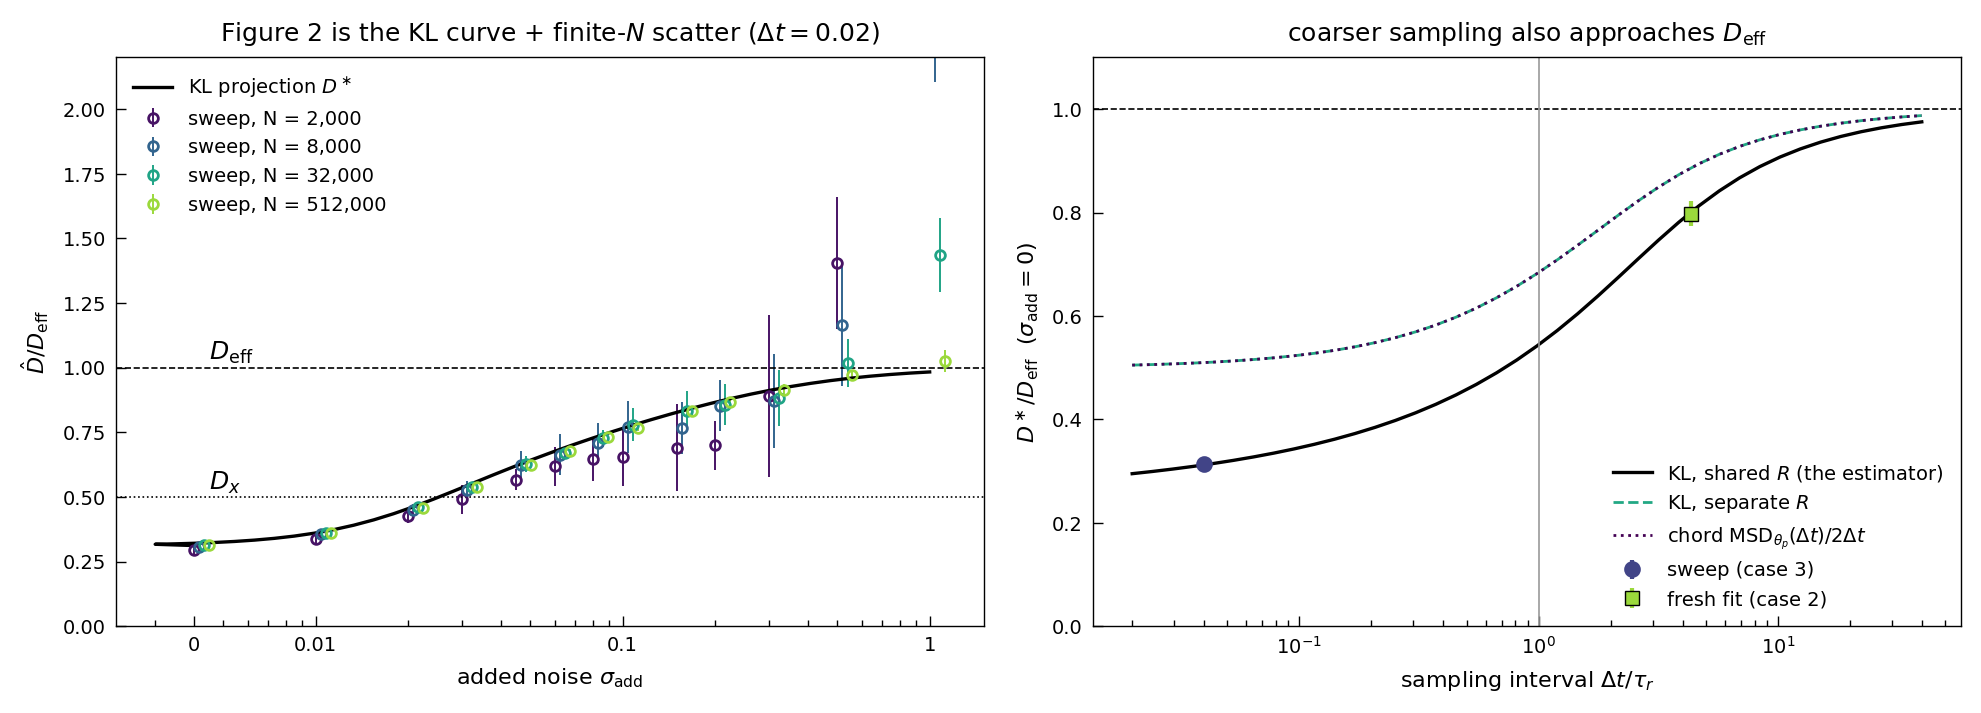

In [16]:
# fresh fit at Delta t = 2.16 (no added noise, supplement case 2), N = 4000 -> T = 8640
DT_CASE2 = 2.16
cfg_dt1 = replace(cfg, delta_t_inf=DT_CASE2, N_INF_max=4000, n_rep=2)
t_start = time.time()
traj_dt1 = NIS.simulate_ensemble(cfg_dt1, thin=True)
fits_dt1 = [NIS.fit_window(*NIS.make_window(traj_dt1, cfg_dt1, 0.0, 4000, m, 0), cfg_dt1) for m in range(2)]
kp_dt1 = kl_projection(0.0, DT_CASE2)
print(f"Delta t = {DT_CASE2} ({time.time() - t_start:.0f} s):  D_map/D_eff = "
      + ", ".join(f"{f['D_map']/D_eff:.3f} ± {f['lnD_std']*f['D_map']/D_eff:.3f}" for f in fits_dt1)
      + f"   KL: {kp_dt1['D']/D_eff:.3f};   R_map = {np.mean([f['R_map'] for f in fits_dt1]):.2e},  KL R* = {kp_dt1['R']:.2e}")

sig_dense = np.concatenate([[0.0], np.geomspace(0.003, 1.0, 40)])
kl_dense = np.array([kl_projection(s, dt_inf)['D'] for s in sig_dense]) / D_eff
dt_dense = np.geomspace(0.01, 20, 40)
kl_dt = np.array([kl_projection(0.0, d)['D'] for d in dt_dense]) / D_eff
kl_dt_sep = np.array([kl_projection(0.0, d, shared_R=False)['D'] for d in dt_dense]) / D_eff

fig, axs = plt.subplots(1, 2, figsize=(10, 3.7))
ax = axs[0]
xplot = lambda s: np.where(s == 0, 0.004, s)          # place sigma_add = 0 at the left edge
Ns = [2000, 8000, 32000, 512000]
for N_, col in zip(Ns, SEQ(len(Ns))):
    g = sweep.query('N_INF == @N_').groupby('sigma_add').D_map.agg(['mean', 'std'])
    ax.errorbar(xplot(g.index.values) * (1 + 0.04 * Ns.index(N_)), g['mean'] / D_eff, g['std'] / D_eff,
                fmt='o', ms=3.5, mfc='none', lw=0.7, capsize=0, color=col, label=f'sweep, N = {N_:,}')
ax.semilogx(xplot(sig_dense), kl_dense, '-', color='k', lw=1.2, label='KL projection $D^\\ast$')
ax.axhline(1, ls='--', lw=0.6, color='k'); ax.axhline(Dx / D_eff, ls=':', lw=0.6, color='k')
ax.text(0.0045, 1.03, r'$D_{\rm eff}$'); ax.text(0.0045, 0.53, r'$D_x$')
ax.set_xticks([0.004, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
ax.set_ylim(0, 2.2)
fs.style_axes(ax, r'added noise $\sigma_{\rm add}$', r'$\hat D/D_{\rm eff}$'); ax.legend(loc='upper left', fontsize=7)
ax.set_title(r'Figure 2 is the KL curve $+$ finite-$N$ scatter ($\Delta t=0.02$)')

ax = axs[1]
ax.semilogx(dt_dense / tau_r, kl_dt, '-', color='k', lw=1.2, label='KL, shared $R$ (the estimator)')
ax.semilogx(dt_dense / tau_r, kl_dt_sep, '--', color=C['model'], lw=1, label='KL, separate $R$')
ax.semilogx(dt_dense / tau_r, msd_theta_p(dt_dense, a, b, Dx) / (2 * dt_dense) / D_eff, ':', color=C['theory'],
            lw=1, label=r'chord $\mathrm{MSD}_{\theta_p}(\Delta t)/2\Delta t$')
g0 = sweep.query('N_INF == 512000 and sigma_add == 0').D_map
ax.errorbar([dt_inf / tau_r], [g0.mean() / D_eff], [g0.std() / D_eff], fmt='o', color=C['data'], ms=5, label='sweep (case 3)')
ax.errorbar([DT_CASE2 / tau_r], [np.mean([f['D_map'] for f in fits_dt1]) / D_eff],
            [np.std([f['D_map'] for f in fits_dt1]) / D_eff], fmt='s', color=C['extra'], ms=5, mec='k', mew=0.5,
            label='fresh fit (case 2)')
ax.axhline(1, ls='--', lw=0.6, color='k'); ax.axvline(1, color='0.6', lw=0.6)
ax.set_ylim(0, 1.1)
fs.style_axes(ax, r'sampling interval $\Delta t/\tau_r$', r'$D^\ast/D_{\rm eff}$  ($\sigma_{\rm add}=0$)')
ax.legend(loc='lower right', fontsize=7); ax.set_title('coarser sampling also approaches $D_{\\rm eff}$')
fig.tight_layout(); plt.show()
assert all(abs(f['D_map'] / kp_dt1['D'] - 1) < 3 * f['lnD_std'] for f in fits_dt1)

**Reading the figure.**
* **Left.** Every budget scatters around the same black curve. Two prior-dominated points ($N=2000$ and $8000$ at $\sigma_{\rm add}=1$, at $4.2$ and $2.3\,D_{\rm eff}$) are off the top of the axis. Increasing $N$ shrinks the scatter but **does not move the points toward $D_{\rm eff}$**. More data make a biased estimate more precise, not more accurate. The visible exceptions (open circles above the curve at small $N$ and large $\sigma_{\rm add}$) are the identifiability failure discussed in §8.
* **Right.** Coarse sampling is an alternative to added noise. With a separate $R$ the KL fit sets $R^\ast=0$, because the coloured part has *positive* lag-one correlation, the opposite of noise. $D^\ast$ then equals exactly the chord diffusivity at lag $\Delta t$ (dashed and dotted curves coincide). Once $\Delta t\gg\tau_r$, consecutive samples see independent amplitudes and the chord diffusivity at lag $\Delta t$ approaches $D_{\rm eff}$. For $\Delta t\gtrsim20\tau_r$ the shared-$R$ curve follows the limiting law $D^\ast/D_{\rm eff}=1-\tau_r/\Delta t$ to better than 1 %, for any $\Delta t$, $b/a$ and $D_x$ (the chord deficit $(b/a)^2\sigma_\rho^2/\Delta t$ plus the shared-$R$ cost $\sigma_\rho^2/\Delta t$); `StuartLandauInference.ipynb` cases 2b and 3b realise $\Delta t/\tau_r\ge200$ with a stiffer amplitude and recover $D_{\rm eff}$ within the 95 % interval without added noise. The shared $R$ (solid vs dashed) costs a further 39 % at $\Delta t=0.02$, 20 % at $\Delta t=\tau_r$, 16 % at $\Delta t=1$, 5 % at $\Delta t=5$ and 2 % at $\Delta t=10$: $R^\ast\to\sigma_\rho^2$ is taken from the radial channel regardless of sampling, so the penalty scales like $\sigma_\rho^2/(D_{\rm eff}\Delta t)$ and fades once the per-sample phase variance $2D\Delta t$ outgrows $\sigma_\rho^2$.

## 7 · How errors propagate, and what you can check on real data

On real data there is no $D_{\rm eff}$ to compare to. Which diagnostics reveal that the model is wrong?

| Quantity | Formula | What a misspecified model does to it |
|---|---|---|
| **innovation whiteness** | $\hat\rho_1=\mathrm{corr}(e_k,e_{k+1})$ of the standardised tangential innovations | slow residual structure that the model forces into "white noise" shows up as $\hat\rho_1>0$ |
| **NIS** | $\overline{\nu^\top S^{-1}\nu}$ | $\approx2$ at the MAP (the stationarity condition in $R$ pins the $(P+R)$- and $R$-weighted residual energies, and $R$ absorbs the scale), so it is **blind** to misspecification |
| **Laplace vs replicate sd** | $\sqrt{(\mathcal I^{-1})_{ii}}$ vs scatter | Laplace is a *within-model* curvature, so it is too narrow when the residuals are not white |
| **$\sigma_\omega$** | $\approx\sqrt{2\hat D/T}$ | inherits the bias in $\hat D$; the honest value is $\sqrt{2D_{\rm eff}/T}$ |
| **phase tracking** | rmse of $\hat\theta$ vs $\theta_p$ and $\Phi$ | tracks $\theta_p$; distance to $\Phi$ floors at $(b/a)\sigma_\rho$ |

We use the $N\le8000$ cells, where every replicate carries a Laplace covariance. Ratios are pooled over $N\in\{2000,4000,8000\}$, because an 8-replicate sd alone has a ≈27 % sampling error.

            acf1   NIS  sd lnD: Laplace/replicates  sd omega: Laplace/replicates  sd omega: sqrt(2 D_eff/T)/replicates  rmse to theta_p  rmse to Phi  coverage(theta_p)  coverage(Phi)
sigma_add                                                                                                                                                                             
0.000      0.770 2.001                       0.769                         0.514                                 0.936            0.009        0.024              0.841          0.401
0.010      0.316 2.001                       0.867                         0.553                                 0.936            0.011        0.025              0.749          0.418
0.020      0.098 2.001                       1.104                         0.631                                 0.951            0.016        0.028              0.661          0.451
0.030      0.035 2.001                       0.892                         0.670     

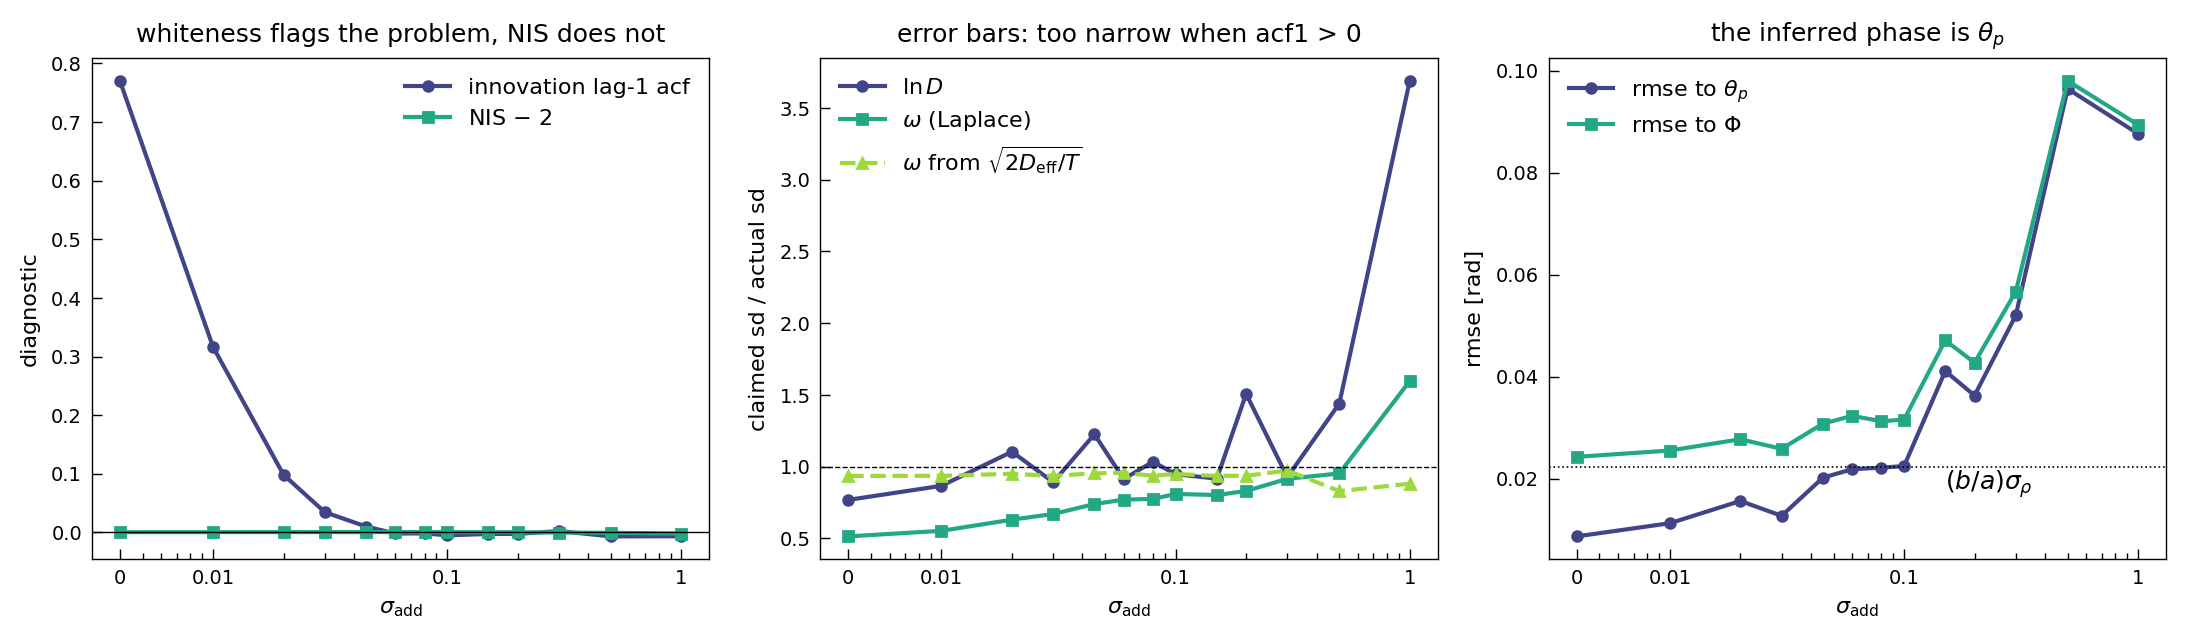

In [17]:
small = sweep.query('N_INF <= 8000')
cell = small.groupby(['N_INF', 'sigma_add']).agg(
    lap_lnD=('lnD_std', 'mean'), rep_lnD=('D_map', lambda x: np.std(np.log(x), ddof=1)),
    lap_w=('omega_std', 'mean'), rep_w=('omega_map', lambda x: x.std(ddof=1)), T=('T', 'mean'))
ratio = pd.DataFrame({'lnD': cell.lap_lnD / cell.rep_lnD, 'w': cell.lap_w / cell.rep_w,
                      'w_eff': np.sqrt(2 * D_eff / cell['T']) / cell.rep_w}).groupby('sigma_add').mean()
g8 = sweep.query('N_INF == 8000').groupby('sigma_add')
diag = pd.DataFrame({
    'acf1': g8.acf1.mean(),
    'NIS': g8.NIS_mean.mean(),
    'sd lnD: Laplace/replicates': ratio['lnD'],
    'sd omega: Laplace/replicates': ratio['w'],
    'sd omega: sqrt(2 D_eff/T)/replicates': ratio['w_eff'],
    'rmse to theta_p': g8.rmse_geo.mean(), 'rmse to Phi': g8.rmse_Phi.mean(),
    'coverage(theta_p)': g8.cov_geo.mean(), 'coverage(Phi)': g8.cov_Phi.mean()})
print(diag.to_string(float_format=lambda v: f'{v:.3f}'))

fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
x = xplot(diag.index.values)
axs[0].semilogx(x, diag.acf1, 'o-', ms=3.5, color=C['data'], label='innovation lag-1 acf')
axs[0].semilogx(x, diag.NIS - 2, 's-', ms=3.5, color=C['model'], label='NIS $-$ 2')
axs[0].axhline(0, color='k', lw=0.5)
fs.style_axes(axs[0], r'$\sigma_{\rm add}$', 'diagnostic'); axs[0].legend()
axs[0].set_title('whiteness flags the problem, NIS does not')

axs[1].semilogx(x, diag['sd lnD: Laplace/replicates'], 'o-', ms=3.5, color=C['data'], label=r'$\ln D$')
axs[1].semilogx(x, diag['sd omega: Laplace/replicates'], 's-', ms=3.5, color=C['model'], label=r'$\omega$ (Laplace)')
axs[1].semilogx(x, diag['sd omega: sqrt(2 D_eff/T)/replicates'], '^--', ms=3.5, color=C['extra'],
                label=r'$\omega$ from $\sqrt{2D_{\rm eff}/T}$')
axs[1].axhline(1, color='k', lw=0.5, ls='--')
fs.style_axes(axs[1], r'$\sigma_{\rm add}$', 'claimed sd / actual sd'); axs[1].legend()
axs[1].set_title('error bars: too narrow when acf1 > 0')

axs[2].semilogx(x, diag['rmse to theta_p'], 'o-', ms=3.5, color=C['data'], label=r'rmse to $\theta_p$')
axs[2].semilogx(x, diag['rmse to Phi'], 's-', ms=3.5, color=C['model'], label=r'rmse to $\Phi$')
axs[2].axhline(b / a * np.sqrt(sig_rho2), color='k', lw=0.6, ls=':')
axs[2].text(0.15, b / a * np.sqrt(sig_rho2) * 0.8, r'$(b/a)\sigma_\rho$')
fs.style_axes(axs[2], r'$\sigma_{\rm add}$', 'rmse [rad]'); axs[2].legend(loc='upper left')
axs[2].set_title('the inferred phase is $\\theta_p$')
for ax in axs:
    ax.set_xticks([0.004, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
fig.tight_layout(); plt.show()

**Propagation, summarised.**
* **Amplitude variance → R → D.** The radial variance enters $R$. Through the shared $R$ it lowers $D$, and through $D$ it shrinks the Laplace $\sigma_\omega$ (left of the middle panel). The $\omega$ *point estimate* is unaffected: it only uses the total phase advance (checked in §7b below).
* **Coloured phase → whiteness.** The short-memory tangential component appears as positively correlated innovations ($\hat\rho_1\approx0.77$ at $\sigma_{\rm add}=0$). $\hat\rho_1\to0$ for $\sigma_{\rm add}\gtrsim0.05$, and the Laplace/actual ratio climbs toward 1 there. At $\sigma_{\rm add}=1$ the ratio exceeds 1, because these small-$N$ fits are prior-dominated (§8). Note that $\sqrt{2D_{\rm eff}/T}$ gives the right $\omega$ error bar at *every* noise level: only the $\hat D$ fed into it is wrong.
* **NIS is useless here.** At the MAP, $R$ is fitted to make it $\approx2$.
* **Phase credible bands** under-cover, because the bands assume the white model. Coverage against $\Phi$ is worse still, because $\Phi$ differs from $\theta_p$ by $(b/a)\rho$, which no observation of the angle can reveal.

### 7b · Check: the $\omega$ point estimate
The checklist's "$\omega$ is unbiased" is tested here against $\omega_{\theta,\rm emp}$, the realised mean frequency of the same window. §1c explains why that, and not $\omega_0=1$, is the reference: the comparison with $1$ shows the Euler–Maruyama shift $b\,dt/2a=10^{-3}$, which is already $+1.6$ sd at the largest budget.


In [18]:
# omega: unbiased against the simulator's realised frequency at every noise level (N = 512000, T = 10240)
big = sweep.query('N_INF == 512000').copy()
se_w = np.sqrt(2 * D_eff / big['T'])                                    # honest sd of omega_map (section 7)
big['z_sim'] = (big.omega_map - big.omega_theta_emp) / se_w             # vs the realised mean frequency
big['z_one'] = (big.omega_map - 1.0) / se_w                             # vs the nominal omega_0 = 1
zt = big.groupby('sigma_add')[['z_sim', 'z_one']].agg(['mean', 'std'])
zt.columns = ['(w_map - w_emp)/sd: mean', 'std', '(w_map - 1)/sd: mean', 'std ']
print(zt.to_string(float_format=lambda v: f'{v:+.3f}'))
print(f"\npooled (omega_map - 1)/sd = {big.z_one.mean():+.2f} +/- {big.z_one.std(ddof=1) / np.sqrt(len(big)):.2f};   "
      f"mean(omega_theta_emp) - 1 = {(big.omega_theta_emp - 1).mean():+.2e}   (Euler-Maruyama b dt/2a = {b * cfg.dt / (2 * a):.1e})")
assert np.all(np.abs(zt.iloc[:, 0]) < 0.05)      # omega_map tracks the realised frequency to < 5 % of one sd


           (w_map - w_emp)/sd: mean    std  (w_map - 1)/sd: mean   std 
sigma_add                                                              
0.000                        +0.000 +0.002                +1.590 +1.276
0.010                        +0.000 +0.002                +1.590 +1.276
0.020                        +0.000 +0.003                +1.590 +1.275
0.030                        -0.001 +0.002                +1.589 +1.275
0.045                        -0.000 +0.004                +1.589 +1.276
0.060                        -0.000 +0.003                +1.589 +1.275
0.080                        +0.001 +0.006                +1.591 +1.274
0.100                        -0.001 +0.004                +1.589 +1.276
0.150                        -0.001 +0.004                +1.588 +1.275
0.200                        +0.003 +0.005                +1.592 +1.275
0.300                        +0.007 +0.008                +1.596 +1.276
0.500                        +0.002 +0.018                +1.592

## 8 · When there is not enough data: identifiability and the prior

§3 showed that at high $\kappa$ the record holds about $N/\sqrt\kappa$ independent pieces of information on $D$, $\mathrm{Var}(\ln D)\approx4\sqrt{2\kappa}/N$. Even at $\sigma_{\rm add}=1$, $N=2000$ ($\kappa^\ast\approx2.5\times10^4$) that is $\mathrm{sd}(\ln D)\approx0.7$: weakly identified, not flat. What goes wrong at small $N$ is the **prior**. `fit_window` seeds $D_{\rm init}=R_{\rm init}/20$ with an inverse-gamma prior of mode $D_{\rm init}$ and curvature $\beta_D/D=2D_{\rm init}/D$ in $\ln D$. Because $R_{\rm init}\approx\tfrac12\sigma_{\rm add}^2$, $D_{\rm init}\propto\sigma_{\rm add}^2$ and the prior curvature at $D^\ast$ grows like $\kappa^\ast$; at $\sigma_{\rm add}=1$ the prior mode is about $10\,D_{\rm eff}$. This is a *data-dependent* prior, and the prior-to-likelihood information ratio scales as $\kappa^{\ast3/2}/N$.

The plot uses $N/\kappa^\ast$, with the pseudo-true $\kappa^\ast=R^\ast/(D^\ast\Delta t)$ from §5, because that is the group the rule of thumb below is stated in. The code also reports how well $\ln(\hat D/D^\ast)$ collapses in $N/\kappa^\ast$, $N/\sqrt{\kappa^\ast}$ and $N/\kappa^{\ast3/2}$ (rms residual about a local linear trend). The $3/2$ power collapses best, as the prior-dominance argument predicts; $N/\sqrt{\kappa^\ast}$, the pure-likelihood group, collapses worst.


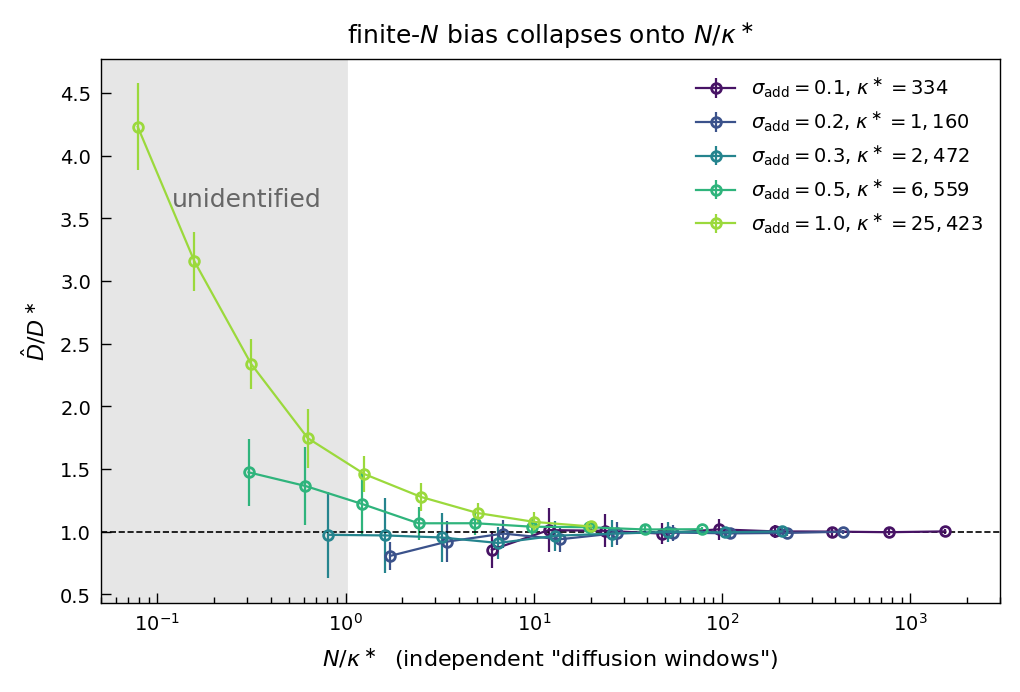

max |D_map/D* - 1| for N/kappa* >= 10: 0.078
max |D_map/D* - 1| for N/kappa* >= 20: 0.042
collapse in N/kappa*       : rms local residual of ln(D_map/D*) = 0.122
collapse in N/sqrt(kappa*) : rms local residual of ln(D_map/D*) = 0.189
collapse in N/kappa*^1.5   : rms local residual of ln(D_map/D*) = 0.069


In [19]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
sigs = [0.1, 0.2, 0.3, 0.5, 1.0]
coll, pts_all = [], []
for sig, col in zip(sigs, SEQ(len(sigs))):
    kp = kl_projection(sig, dt_inf)
    kappa_star = kp['R'] / (kp['D'] * dt_inf)
    g = sweep.query('sigma_add == @sig').groupby('N_INF').D_map.agg(['mean', 'std'])
    ax.errorbar(g.index / kappa_star, g['mean'] / kp['D'], g['std'] / kp['D'], fmt='o-', ms=3.5, lw=0.8,
                mfc='none', color=col, label=fr'$\sigma_{{\rm add}}={sig}$, $\kappa^\ast={kappa_star:,.0f}$')
    coll += [(n / kappa_star, m / kp['D']) for n, m in zip(g.index, g['mean'])]
    pts_all += [(n, kappa_star, m / kp['D']) for n, m in zip(g.index, g['mean'])]
ax.axhline(1, color='k', lw=0.6, ls='--'); ax.axvspan(1e-2, 1, color='0.9', zorder=0)
ax.text(0.12, 3.6, 'unidentified', color='0.4')
ax.set_xscale('log'); ax.set_xlim(0.05, 3e3)
fs.style_axes(ax, r'$N/\kappa^\ast$  (independent "diffusion windows")', r'$\hat D/D^\ast$')
ax.legend(fontsize=7); ax.set_title('finite-$N$ bias collapses onto $N/\\kappa^\\ast$')
fig.tight_layout(); plt.show()
coll = np.array(coll)
for thr in (10, 20):
    print(f"max |D_map/D* - 1| for N/kappa* >= {thr}: {np.max(np.abs(coll[coll[:, 0] >= thr, 1] - 1)):.3f}")
assert np.all(np.abs(coll[coll[:, 0] >= 10, 1] - 1) < 0.10)
assert np.all(np.abs(coll[coll[:, 0] >= 20, 1] - 1) < 0.05)

# which dimensionless group collapses the finite-N bias? rms residual of ln(D_map/D*) about a local linear trend
pts = pd.DataFrame(pts_all, columns=['N', 'kappa', 'ratio'])
resid = {}
for name, pw in (('N/kappa*', 1.0), ('N/sqrt(kappa*)', 0.5), ('N/kappa*^1.5', 1.5)):
    x = np.log10(pts.N / pts.kappa**pw).values; y = np.log(pts.ratio.values)
    o = np.argsort(x); x, y = x[o], y[o]
    res = [y[i] - np.polyval(np.polyfit(x[max(0, i - 3):i + 4], y[max(0, i - 3):i + 4], 1), x[i]) for i in range(len(x))]
    resid[name] = float(np.sqrt(np.mean(np.square(res))))
    print(f"collapse in {name:15s}: rms local residual of ln(D_map/D*) = {resid[name]:.3f}")
assert resid['N/kappa*^1.5'] < resid['N/kappa*'] < resid['N/sqrt(kappa*)']


**Rule of thumb:** the mean fit is within 8 % of $D^\ast$ once $N/\kappa^\ast\ge10$, and within 5 % once $N/\kappa^\ast\ge20$. Trust $\hat D$ only when $N\gtrsim10$–$20\,\kappa$, with $\kappa=\hat R/(\hat D\Delta t)$ computed from the fit itself. Below $N/\kappa\approx2$ the estimate is mostly prior and initialisation. The Laplace sd is then large but still *understates* the problem, because the prior is narrow. This is an empirical, conservative bound for this pipeline's seeding rule ($D_{\rm init}=R_{\rm init}/20$); a different seed moves the boundary, and the Fisher bound alone would allow $N\sim\sqrt\kappa$.

**EKF breakdown** (step D in the roadmap) is the other failure. The EKF needs $\sqrt{P_{k\mid k-1}}\ll1$ rad, and its pseudo-observation $r_k\sin\delta_k$ saturates once the angular noise $\sigma_\psi\approx\sigma_{\rm add}$ approaches 1 rad. At $\sigma_{\rm add}=0.5$–1 we cannot cleanly separate this from the finite-$N$ bias with the present sweep: the 512k points still sit 2–4 % above $D^\ast$. To be safe, keep $\sigma_\psi\lesssim0.3$ rad.

Two further hard limits follow from the sampling:
* **Nyquist:** $\omega\Delta t<\pi$, or the phase winding aliases.
* **No cycle slips:** $\sqrt{2D\Delta t}\ll\pi$, so the phase step per sample stays unambiguous.

## 9 · Regime map and checklist

The map shows the pseudo-true $D^\ast/D_{\rm eff}$ over the two experimental knobs, the added noise and the sampling interval. It is overlaid with the boundaries derived above. The identifiability boundary $N=10\kappa^\ast$ (empirical, §8) is drawn for a record of $N=32{,}000$ samples.

regime map: 324 KL projections in 56 s


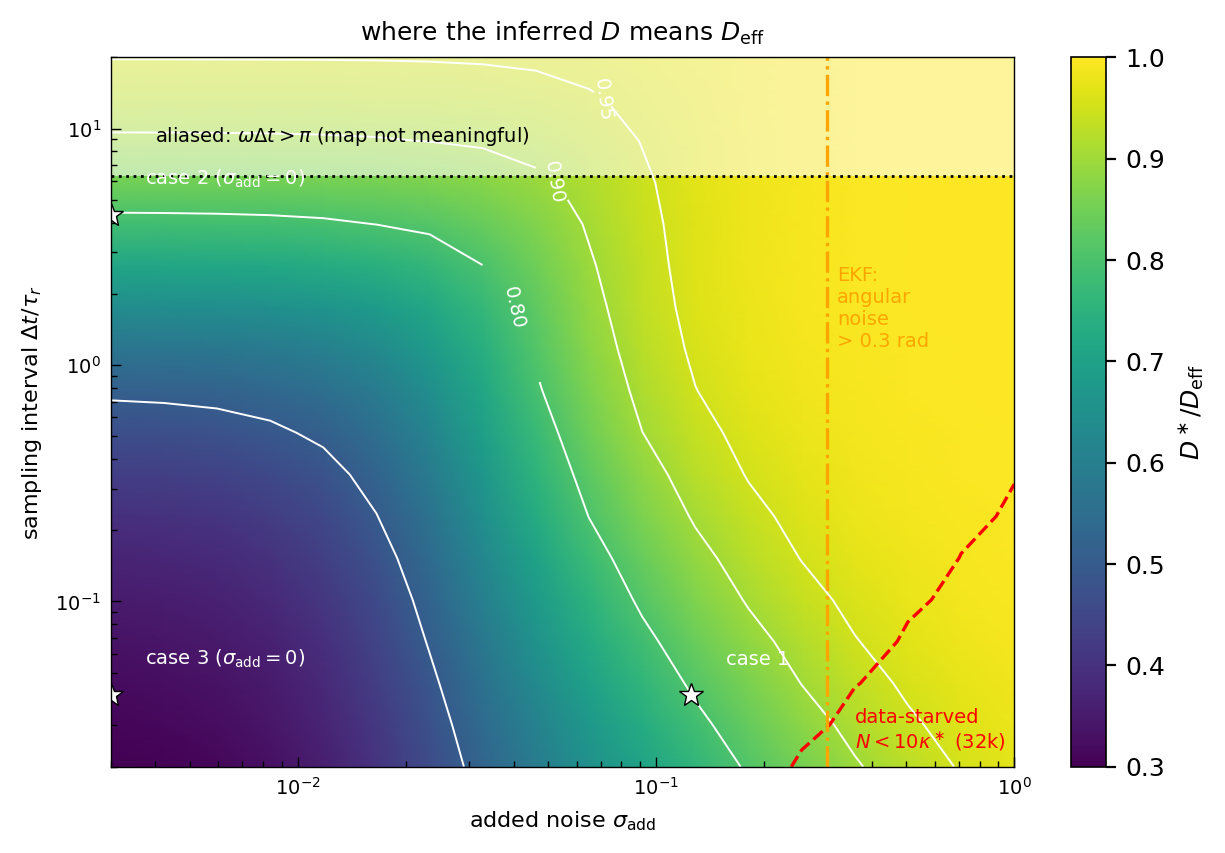

In [20]:
sig_ax = np.geomspace(3e-3, 1.0, 18)
dt_ax = np.geomspace(0.01, 10.0, 18)
t_start = time.time()
Dmap = np.array([[kl_projection(s, d)['D'] / D_eff for s in sig_ax] for d in dt_ax])
Rmap = np.array([[kl_projection(s, d)['R'] for s in sig_ax] for d in dt_ax])
print(f"regime map: {Dmap.size} KL projections in {time.time() - t_start:.0f} s")
kappa_map = Rmap / (Dmap * D_eff * dt_ax[:, None])

fig, ax = plt.subplots(figsize=(6.4, 4.4))
pc = ax.pcolormesh(sig_ax, dt_ax / tau_r, Dmap, cmap='viridis', vmin=0.3, vmax=1.0, shading='gouraud')
cs = ax.contour(sig_ax, dt_ax / tau_r, Dmap, levels=[0.5, 0.8, 0.9, 0.95], colors='w', linewidths=0.7)
ax.clabel(cs, fmt='%.2f', fontsize=7)
ax.contour(sig_ax, dt_ax / tau_r, 32000 / kappa_map, levels=[10], colors='r', linewidths=1.2, linestyles='--')
ax.axvline(0.3, color='orange', lw=1.2, ls='-.')
ax.axhline(np.pi / tau_r, color='k', lw=1.0, ls=':')       # omega dt = pi with omega = 1
ax.axhspan(np.pi / tau_r, dt_ax[-1] / tau_r, color='w', alpha=0.55, lw=0)
ax.text(0.004, np.pi / tau_r * 1.4, r'aliased: $\omega\Delta t>\pi$ (map not meaningful)', fontsize=7)
ax.text(0.32, 1.2, 'EKF:\nangular\nnoise\n> 0.3 rad', color='orange', fontsize=7)
ax.text(0.36, 0.024, 'data-starved\n' + r'$N<10\kappa^\ast$ (32k)', color='r', fontsize=7)
# the three cases of StuartLandauInference.ipynb (sigma_add = 0 is placed at the left edge of the log axis)
for s_, d_, lab_ in ((0.125, dt_inf, 'case 1'), (sig_ax[0], 2.16, r'case 2 ($\sigma_{\rm add}=0$)'), (sig_ax[0], dt_inf, r'case 3 ($\sigma_{\rm add}=0$)')):
    ax.plot([s_], [d_ / tau_r], 'w*', ms=9, mec='k', mew=0.5)
    ax.text(s_ * 1.25, d_ / tau_r * 1.35, lab_, color='w', fontsize=7)
ax.set_xscale('log'); ax.set_yscale('log')
cb = fig.colorbar(pc, ax=ax); cb.set_label(r'$D^\ast/D_{\rm eff}$')
fs.style_axes(ax, r'added noise $\sigma_{\rm add}$', r'sampling interval $\Delta t/\tau_r$')
ax.set_title(r'where the inferred $D$ means $D_{\rm eff}$')
fig.tight_layout(); plt.show()

**How to read the map.** You are estimating $D_{\rm eff}$ to within 10 % only in the bright region (contour 0.9). It is bounded:
* on the right by EKF breakdown (orange);
* above by aliasing (dotted);
* on the left, at large noise, by data starvation (red dashed: to the right of it you need more than $N$ samples).

At fine sampling and low noise, the regime of most experiments, the estimator returns a mixture of $D_x$ and $D_{\rm eff}$ diluted further by the shared $R$. Its value is $D^\ast$ from §5, not either physical diffusivity. Note that at $a=b=1$ the noise-free route upward is closed: Nyquist caps $\Delta t/\tau_r$ at $2\pi$, i.e. $D^\ast\le0.85\,D_{\rm eff}$. Recovering $D_{\rm eff}$ without noise needs $\tau_r\ll\Delta t<\pi/\omega$, an amplitude that relaxes much faster than the oscillation (`StuartLandauInference.ipynb` cases 2b, 3b).

### Checklist

| Condition | Dimensionless test | If violated | Diagnostic on real data |
|---|---|---|---|
| weak noise (phase reduction valid) | $\sigma_\rho\ll1$ (radial spread of $\lvert y\rvert$) | $\Phi$ undefined, no single $D$ | histogram of $\lvert y\rvert$ |
| amplitude memory resolved away | $\tau^\ast=\sqrt{R\Delta t/2D}\gg\tau_r$ **or** $\Delta t\gg\tau_r$ | $D^\ast<D_{\rm eff}$ (§5) | innovation acf1 $>0$; $\hat D$ changes when you add noise or decimate |
| isotropic residuals | radial residual var $\approx$ tangential | shared $R$ biases $D$ down | compare $\overline{o_k}$ with $\overline{(z_k-\hat\theta_k)^2}$ (§2) |
| enough data | $N\gtrsim10\,\kappa$ (empirical, §8), $\kappa=\hat R/\hat D\Delta t$ | prior/initialisation dominated, usually biased up | $\hat D$ vs $N$ on sub-windows; posterior ≈ prior |
| EKF linearisation | $2D\Delta t\ll1$ (bias $\approx-(2$–$2.5)\times2D\Delta t$ in $\ln D$), $3P_{k\mid k-1}^2/8R\ll1$, angular noise $\lesssim0.3$ rad | $\hat D$ low, $\hat R$ high; saturation, slips | refit after decimating by 2: the bias doubles if it is EKF bias |
| no aliasing | $\omega\Delta t<\pi$ | wrong $\omega$ | FFT peak near Nyquist |
| honest error bars | innovations white | Laplace too narrow | acf1; replicate / block-bootstrap sd |
| $\omega$ reference | — | $\omega$ is unbiased, but $\sigma_\omega\propto\sqrt{\hat D}$ | use $\sqrt{2\hat D_{\rm corrected}/T}$ |

### One-paragraph summary
The algorithm is a Kalman smoother for a **random walk seen through white noise**. It learns $D$ from the low-frequency part of the angle increments and $R$ from the high-frequency part *and* from the radial spread of the measurements. On a real limit cycle, amplitude fluctuations violate both channels' assumptions. The angle carries a coloured, anti-diffusive component $-(b/a)\rho$, and the radius carries variance that is not measurement noise. The estimator then converges to the KL-closest random walk, $D^\ast$, which can be computed in closed form for Stuart–Landau and matches the fits to 1 %. It reaches $D_{\rm eff}$ only when the information window $\sqrt{R\Delta t/2D}$ or the sampling interval exceeds the amplitude relaxation time, and the record is long enough ($N\gtrsim10\kappa$ for this pipeline's seeding) that the data-dependent prior no longer matters. Innovation whiteness tells you which side of that line you are on.

## 10 · Asymptotic limits: when does the model work out of the box?

Everything above reduces to three dimensionless numbers:
$$
\frac{\tau_r}{\Delta t}=\frac{1}{2a\Delta t}\ \ (\text{amplitude memory per sample}),\qquad
2D_{\rm eff}\Delta t\ \ (\text{phase step per sample}),\qquad
\kappa=\frac{R}{D\Delta t}\ \ (\text{noise per step; information window }\tau^\ast/\tau_r=\sqrt{\kappa/2}\,\Delta t/\tau_r),
$$
plus Nyquist, $\omega\Delta t<\pi$, and the record length $N$. The table collects the limits derived in this notebook ($D^\ast$ is the large-$N$ value of $\hat D$; "works" means $D_{\rm eff}$ falls inside the 95 % interval, whose half-width is $1.96\sqrt{2/N}\approx1.5\,\%$ at $N=32000$ without noise).

| limit | $D^\ast/D_{\rm eff}$ | mechanism | § | works out of the box? |
|---|---|---|---|---|
| data generated by the model (Example 1b) | $1-2.4\times2D\Delta t$ | EKF linearisation only | 3d | **yes**, if $2D\Delta t\ll1$ and $N\gtrsim10\kappa$ |
| no noise, $\Delta t\gg\tau_r$ | $1-\tau_r/\Delta t$ | amplitude variance per sample: shared kick $(b/a)^2\sigma_\rho^2/\Delta t$ + radial channel $\sigma_\rho^2/\Delta t$ | 5b | **yes**, if $\tau_r\ll\Delta t$, $2.4\times2D_{\rm eff}\Delta t\ll1$ and $\omega\Delta t<\pi$; at $a=b=1$ these are incompatible ($\Delta t/\tau_r<2\pi\Rightarrow D^\ast\le0.85$), realised with a stiffer amplitude in `StuartLandauInference` cases 2b, 3b |
| no noise, $\Delta t\ll\tau_r$ | $\to\dfrac{1}{2(1+b^2/a^2)}$ ($=0.25$ at $a=b$; $0.31$ at $\Delta t=0.02$) | radial channel pins $R$; forced white noise halves $Q$ | 5c | **no**; returns neither $D_x$ nor $D_{\rm eff}$ |
| isochronous, $b\to0$, $\Delta t\ll\tau_r$ | $1/2$ | same halving; $D_{\rm eff}=D_x$ does not help | 5c | **no** |
| added noise, $\sigma_{\rm add}\to\infty$ | $\to1$ ($0.91$ at $\sigma_{\rm add}=0.3$, $0.98$ at $1$) | information window $\tau^\ast=\sqrt{R\Delta t/2D}\gg\tau_r$ hides the dip; $R_{\rm t}\approx R$ removes the halving | 4b, 5c | **yes**, if $\sigma_\psi\lesssim0.3$ rad (EKF) and $N\gtrsim10\kappa$; this is Figure 2 |
| weak noise, $D_x\to0$ | unchanged | every term in $D^\ast$ is $\propto D_x$; the bias is a ratio of time scales | 5b | **no help** |
| long record, $N\to\infty$ | unchanged, sd $\to0$ | $D^\ast$ is the large-$N$ limit | 6 | **no help**: more data make the biased value more precise |
| stiff amplitude, $a\to\infty$ at fixed $\Delta t$ | $1-1/(2a\Delta t)$ | same as $\Delta t\gg\tau_r$ | 5b | **yes** (cases 2b, 3b) |
| strong shear, $b/a\to\infty$ | $1-\tau_r/\Delta t$ (coarse), $\to0$ (fine) | the deficit moves from the radial to the tangential channel but its sum is fixed | 5b, 5c | as above |

**In one sentence:** the random-walk + white-noise model is the correct coarse-grained description of a noisy limit cycle only when the amplitude relaxes within one sampling interval, $\tau_r\ll\Delta t$ (or when added noise makes the filter blind to lags shorter than $\tau_r$); at finer sampling the amplitude memory is read as measurement noise and the estimate sits between $D_x/2$ and $D_{\rm eff}$, at the computable $D^\ast$ of §5, no matter how weak the noise or how long the record.

**The two recipes to get $D_{\rm eff}$ from a real oscillator.**
1. *Decimate.* Choose $\Delta t$ with $\tau_r\ll\Delta t<\pi/\omega$ and $2.4\times2\hat D\Delta t$ below the target precision. This needs $\tau_r\ll\pi/\omega$: the amplitude must relax within a fraction of a period. Then $\hat D=D_{\rm eff}(1-\tau_r/\Delta t)$ and the residual bias can be corrected if $\tau_r$ is known (e.g. from the radial autocorrelation of $|y|$).
2. *Add noise.* Inject isotropic noise with $\sqrt{R\Delta t/2D}\gg\tau_r$, keep $\sigma_\psi\lesssim0.3$ rad and $N\gtrsim10\kappa$. The estimate goes to $D_{\rm eff}$ at the price of the $\sqrt\kappa$ loss in precision of §3.

Both recipes are versions of the same statement: **remove the filter's access to lags shorter than $\tau_r$.** The diagnostic for whether you are there is the innovation whiteness of §7.


In [21]:
print(f"notebook runtime: {time.time() - T0_NOTEBOOK:.0f} s")

notebook runtime: 205 s
